# Pipeline lengkap: deteksi akun mirip-bot di GH Archive (MongoDB Atlas)

Notebook ini menyatukan empat notebook terpisah menjadi satu alur.

| Bagian | Isi |
|---|---|
| **Pengaturan** | Satu sel berisi semua parameter dan saklar, lalu satu sel persiapan bersama (Drive, pustaka, fungsi umum). |
| **1. Unduh GH Archive** | Unduh log per jam, saring tipe event dan field yang dipakai, simpan ke Google Drive. |
| **2. Muat ke Atlas** | Periksa kesehatan jam, muat dua blok jam bersih ke `ghbots.raw_events`, buat indeks, verifikasi. |
| **3. Profil, model, sinkron** | Profil per akun dengan `$group` + `$merge`, Isolation Forest, K-Means, PCA, validasi, ekspor CSV, sinkron ke `ghbots.user_scores`. |
| **4. Benchmark kueri** | Waktu kueri dengan dan tanpa indeks (dengan checkpoint). |

> **Jalankan berurutan** dari atas ke bawah (*Runtime → Run all* boleh). Sel Pengaturan dan Persiapan bersama harus dijalankan lebih dulu di setiap sesi baru. Bagian yang sudah selesai (data di Drive atau di Atlas) bisa dilewati lewat saklar `SKIP_UNDUH` dan `SKIP_MUAT`.

**Yang perlu diingat**
- Semua waktu memakai **UTC** (WIB = UTC + 7).
- Berkas di Drive memuat username GitHub. Simpan privat, jangan diunggah ke repo publik.
- Connection string Atlas jangan ditempel di sel atau dicetak. Notebook membacanya dari Secret Colab `MONGODB_URI`, lalu variabel lingkungan, lalu kotak sandi. Untuk pseudonim yang konsisten antar sesi, tambahkan juga secret `HMAC_KEY`.
- Akun yang ditandai tinggi adalah **kandidat mirip-bot**, bukan bot yang terbukti.

# Pengaturan

Satu-satunya sel yang perlu kamu edit. Semua bagian di bawah membaca nilai dari sini.

In [12]:
#@title Pengaturan { display-mode: "form" }

# ===================== Saklar alur =====================
# True = lewati bagian itu (hasilnya sudah ada di Drive / Atlas).
SKIP_UNDUH       = True   #@param {type:"boolean"}
SKIP_MUAT        = True   #@param {type:"boolean"}
# Hati-hati: True menghapus raw_events dan ingest_log lalu memuat dari nol (profil ikut dihitung ulang).
# Tidak boleh bersamaan dengan SKIP_MUAT = True.
HAPUS_DAN_ULANG  = False   #@param {type:"boolean"}
# True = hapus user_profiles lama lalu agregasi ulang. False = pakai yang ada kalau sudah berisi.
HITUNG_ULANG     = False   #@param {type:"boolean"}
# True = jalankan sel opsional (ringkasan event per akun di Bagian 1, hitung hasil uji manual di Bagian 3).
JALANKAN_OPSIONAL = True  #@param {type:"boolean"}

# ===================== Penyimpanan =====================
# "drive" = Google Drive (aman kalau sesi Colab putus). "lokal" = disk sementara Colab.
SIMPAN_DI     = "drive"          #@param ["drive", "lokal"]
FOLDER_DATA   = "gh-bot-data"    #@param {type:"string"}
FOLDER_HASIL  = "gh-bot-hasil"   #@param {type:"string"}
NAMA_DB       = "ghbots"         #@param {type:"string"}

# ===================== Bagian 1: unduh =====================
# Rentang 2 bulan (UTC). Dari sini dipakai dua blok jam bersih A dan B (lihat Bagian 2).
TANGGAL_MULAI   = "2026-07-25"   #@param {type:"date"}
TANGGAL_SELESAI = "2026-10-25"   #@param {type:"date"}
UNDUH_PARALEL   = 4              #@param {type:"slider", min:1, max:6, step:1}
# Pengaman: berhenti kalau perkiraan total unduhan melebihi batas ini.
BATAS_UNDUH_GB  = 60             #@param {type:"number"}

# ===================== Bagian 2: muat ke Atlas =====================
# Dua blok jam bersih (UTC), format "YYYY-MM-DD JAM", kedua ujung ikut dihitung. JAM tanpa nol di depan.
BLOK_A_MULAI    = "2026-10-11 8"    #@param {type:"string"}
BLOK_A_SELESAI  = "2026-10-14 13"   #@param {type:"string"}
BLOK_B_MULAI    = "2026-10-19 12"   #@param {type:"string"}
BLOK_B_SELESAI  = "2026-10-22 13"   #@param {type:"string"}
# Jam dianggap sehat kalau baris mentahnya (n_in di manifest) minimal segini (jam normal 40.000-90.000).
BATAS_SEHAT     = 25000             #@param {type:"number"} 
# Berapa jam boleh hilang/tidak sehat sebelum berhenti. 0 = ketat.
TOLERANSI_JAM   = 0                 #@param {type:"integer"}
PEKERJA_MUAT    = 8                 #@param {type:"slider", min:1, max:8, step:1}
BATCH_MUAT      = 5000              #@param {type:"integer"}

# ===================== Bagian 3: profil dan model =====================
# Profil disimpan untuk akun dengan paling sedikit MIN_PROFIL event; model dijalankan di ambang MIN_MODEL.
MIN_PROFIL      = 10                #@param {type:"integer"}
MIN_MODEL       = 20                #@param {type:"integer"}
TOP_PERSEN      = 5                 #@param {type:"number"}
K_MAKS          = 8                 #@param {type:"integer"}
SEED            = 42                #@param {type:"integer"}
PEKERJA_PROFIL  = 3                 #@param {type:"slider", min:1, max:6, step:1}
UKURAN_CHUNK    = 5000              #@param {type:"integer"}
BATCH_SINKRON   = 2000              #@param {type:"integer"}
MIN_POSITIF     = 5                 #@param {type:"integer"}
# Uji manual: berkas penilaian dibuat kalau belum ada (tidak menimpa penilaian yang sudah terisi).
BUAT_SAMPEL_MANUAL  = True          #@param {type:"boolean"}
TIMPA_SAMPEL_MANUAL = False         #@param {type:"boolean"}
N_PER_KELOMPOK      = 15            #@param {type:"integer"}
# True (dan JALANKAN_OPSIONAL = True) = hitung kesepakatan setelah kedua penilai mengisi CSV.
HITUNG_UJI_MANUAL   = True         #@param {type:"boolean"}

# ===================== Bagian 4: benchmark kueri =====================
# Awal rentang uji (UTC). Kosong = awal blok A. Jendela dibuat kecil-sedang supaya sesi selesai ~15-30 menit.
MULAI_UJI            = ""                #@param {type:"string"}
UKURAN_JAM           = "6,12,24,48,78"   #@param {type:"string"}
ULANGI               = 3                 #@param {type:"slider", min:1, max:7, step:1}
# Tanpa indeks (COLLSCAN) memindai seluruh koleksi, jadi mahal: hanya sebagian ukuran, ulangan lebih sedikit.
UKURAN_TANPA_INDEKS  = "6,24,78"         #@param {type:"string"}
ULANGI_TANPA_INDEKS  = 1                 #@param {type:"slider", min:1, max:3, step:1}
BATAS_DETIK          = 150               #@param {type:"integer"}

## Persiapan bersama

Dijalankan sekali: pasang dan impor pustaka, pasang Google Drive, tentukan folder, periksa pengaturan, dan definisikan fungsi yang dipakai semua bagian. Koneksi MongoDB dibuat sekali di awal Bagian 2 (Bagian 1 tidak butuh Atlas).

In [13]:
import getpass, gzip, hashlib, hmac, importlib, json, os, shutil, statistics, subprocess, sys, threading, time, zlib
import multiprocessing as mp
from collections import Counter
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor, as_completed
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

def pastikan(modul, paket):
    try:
        importlib.import_module(modul)
    except ImportError:
        print(f"Memasang {paket} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paket],
                       stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=True)

pastikan("pymongo", "pymongo"); pastikan("dns", "dnspython"); pastikan("tqdm", "tqdm"); pastikan("joblib", "joblib")
try:
    pastikan("orjson", "orjson")      # JSON 3-5x lebih cepat; kalau gagal dipasang, json biasa dipakai
except Exception:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import urllib3
from matplotlib.ticker import FuncFormatter
from tqdm.auto import tqdm
from pymongo import ASCENDING, MongoClient, UpdateOne
from pymongo.errors import (AutoReconnect, BulkWriteError, ConfigurationError, ExecutionTimeout,
                            OperationFailure, ServerSelectionTimeoutError)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, cohen_kappa_score, roc_auc_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr

try:
    from IPython.display import display
except ImportError:
    display = print

try:
    import orjson
    loads, dumps = orjson.loads, orjson.dumps
except ImportError:
    loads = json.loads
    dumps = lambda o: json.dumps(o, separators=(",", ":")).encode()

# ---- pemeriksaan pengaturan ----
if SKIP_MUAT and HAPUS_DAN_ULANG:
    raise ValueError("SKIP_MUAT dan HAPUS_DAN_ULANG tidak boleh sama-sama True.")
if SIMPAN_DI not in ("drive", "lokal"):
    raise ValueError("SIMPAN_DI harus 'drive' atau 'lokal'.")

# ---- fungsi umum ----
angka_id = lambda n: f"{n:,.0f}".replace(",", ".")          # 1.234.567

def baca_jam(teks):
    """'2026-10-11 8' -> datetime UTC (naif) 2026-10-11 08:00."""
    tgl, jam = teks.split()
    return datetime.fromisoformat(tgl) + timedelta(hours=int(jam))

def ambil_rahasia(nama, wajib=False, prompt=None):
    """Urutan: Secret Colab -> variabel lingkungan -> kotak sandi (hanya kalau wajib)."""
    try:
        from google.colab import userdata
        v = userdata.get(nama)
        if v:
            return v
    except Exception:
        pass
    v = os.environ.get(nama)
    if v:
        return v
    if wajib:
        return getpass.getpass(prompt or f"Tempel {nama} (tidak ditampilkan): ").strip()
    return None

# ---- folder: Drive dipasang sekali ----
BASE_DIR = None
if SIMPAN_DI == "drive":
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE_DIR = Path("/content/drive/MyDrive")
    except Exception as e:
        print(f"Google Drive tidak bisa dipasang ({type(e).__name__}). Folder disimpan di disk lokal sementara.")
if BASE_DIR is None:
    BASE_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
DIR_UNDUH = BASE_DIR / FOLDER_DATA        # hasil Bagian 1, sumber Bagian 2
DIR_HASIL = BASE_DIR / FOLDER_HASIL       # CSV/grafik Bagian 3 dan 4
DIR_UNDUH.mkdir(parents=True, exist_ok=True)
DIR_HASIL.mkdir(parents=True, exist_ok=True)
MANIFEST = DIR_UNDUH / "manifest.jsonl"

def baca_manifest():
    """Catatan terakhir per jam dari manifest.jsonl -> dict {nama_jam: catatan}."""
    data = {}
    if MANIFEST.exists():
        for baris in MANIFEST.read_text().splitlines():
            if baris.strip():
                r = json.loads(baris)
                data[r["hour"]] = r
    return data

# ---- turunan pengaturan ----
BLOK_RENTANG = {"A": (BLOK_A_MULAI, BLOK_A_SELESAI), "B": (BLOK_B_MULAI, BLOK_B_SELESAI)}
T0_UJI = baca_jam(MULAI_UJI.strip() or BLOK_A_MULAI)
UKURAN_UJI = [int(x) for x in UKURAN_JAM.replace(" ", "").split(",") if x]
UKURAN_UJI_TANPA = {int(x) for x in UKURAN_TANPA_INDEKS.replace(" ", "").split(",") if x}

print(f"Data mentah : {DIR_UNDUH}")
print(f"Hasil       : {DIR_HASIL}")
print(f"Saklar      : SKIP_UNDUH={SKIP_UNDUH} SKIP_MUAT={SKIP_MUAT} HAPUS_DAN_ULANG={HAPUS_DAN_ULANG} HITUNG_ULANG={HITUNG_ULANG}")

Mounted at /content/drive
Data mentah : /content/drive/MyDrive/gh-bot-data
Hasil       : /content/drive/MyDrive/gh-bot-hasil
Saklar      : SKIP_UNDUH=True SKIP_MUAT=True HAPUS_DAN_ULANG=False HITUNG_ULANG=False


# Bagian 1: Unduh data GH Archive

Mengunduh log aktivitas publik GitHub per jam dari [GH Archive](https://www.gharchive.org/), menyaring hanya tipe event dan field yang dipakai, lalu menyimpannya per jam dalam berkas kecil di Drive. **Tidak butuh akun MongoDB Atlas.**

- Jendela waktu diatur di sel Pengaturan (`TANGGAL_MULAI` sampai `TANGGAL_SELESAI`, default 2 bulan). Dua blok jam bersih A dan B yang dimuat di Bagian 2 harus berada di dalam rentang ini.
- Kalau sesi terputus, jalankan lagi. Jam yang sudah selesai dilewati (dicatat di `manifest.jsonl`).
- Berkas mentah tidak disimpan: tiap jam diunduh, disaring, lalu berkas mentahnya dihapus.
- **Sudah pernah selesai?** Set `SKIP_UNDUH = True` di Pengaturan, semua sel Bagian 1 akan dilewati.

## 1.1 Persiapan unduhan
Memeriksa tanggal dan menyusun daftar jam.

In [14]:
if not SKIP_UNDUH:

    BASE_URL = "https://data.gharchive.org"
    HEADERS = {"User-Agent": "pbl-dataviz-gh-bot/1.0 (tugas kuliah)"}

    # Tipe event yang dipakai proyek (sesuai skema raw_events). Sisanya dibuang.
    TIPE_DIPAKAI = {
        "PushEvent", "WatchEvent", "ForkEvent", "IssuesEvent", "IssueCommentEvent",
        "PullRequestEvent", "PullRequestReviewEvent", "PullRequestReviewCommentEvent", "CreateEvent",
    }

    # ---- tanggal ----
    d_mulai = date.fromisoformat(TANGGAL_MULAI)
    d_selesai = date.fromisoformat(TANGGAL_SELESAI)
    kemarin = datetime.now(timezone.utc).date() - timedelta(days=1)
    if d_selesai > kemarin:
        print(f"TANGGAL_SELESAI dipotong ke {kemarin}: hari UTC yang belum berakhir datanya belum lengkap.")
        d_selesai = kemarin
    if d_mulai > d_selesai:
        raise ValueError("TANGGAL_MULAI harus sama dengan atau sebelum TANGGAL_SELESAI.")

    JAM = [(d_mulai + timedelta(days=d), h) for d in range((d_selesai - d_mulai).days + 1) for h in range(24)]

    def nama_jam(tgl, jam):
        return f"{tgl:%Y-%m-%d}-{jam}"          # GH Archive: jam tanpa nol di depan (...-0 sampai ...-23)

    def url_jam(tgl, jam):
        return f"{BASE_URL}/{nama_jam(tgl, jam)}.json.gz"

    TMP = Path("/tmp/gh-unduh")
    TMP.mkdir(parents=True, exist_ok=True)

    print(f"Jendela   : {d_mulai} sampai {d_selesai} (UTC), {len(JAM)} jam")
    print(f"Tujuan    : {DIR_UNDUH}")
    print(f"Ruang sisa: {shutil.disk_usage(DIR_UNDUH).free / 1e9:,.1f} GB")
else:
    print('SKIP_UNDUH = True: Bagian 1 dilewati.')

SKIP_UNDUH = True: Bagian 1 dilewati.


## 1.2 Cek ukuran sebelum mengunduh
Hanya menanyakan ukuran tiap berkas ke server. Kalau perkiraan total melebihi `BATAS_UNDUH_GB`, proses berhenti di sini.

In [15]:
if not SKIP_UNDUH:
    def cek_ukuran(item):
        tgl, jam = item
        try:
            r = requests.head(url_jam(tgl, jam), headers=HEADERS, timeout=20, allow_redirects=True)
            if r.status_code == 404:
                return item, "belum_ada", None
            ukuran = int(r.headers["Content-Length"]) if r.ok and "Content-Length" in r.headers else None
            return item, ("ada" if r.ok else f"http_{r.status_code}"), ukuran
        except requests.RequestException as e:
            return item, f"galat_{type(e).__name__}", None

    with ThreadPoolExecutor(8) as ex:
        cek = list(tqdm(ex.map(cek_ukuran, JAM), total=len(JAM), desc="Cek ukuran"))

    belum_ada = [it for it, s, _ in cek if s == "belum_ada"]
    bisa_diunduh = [(it, u) for it, s, u in cek if s != "belum_ada"]
    ukuran_tahu = [u for _, u in bisa_diunduh if u]
    if not bisa_diunduh:
        raise RuntimeError("Tidak ada berkas yang tersedia di rentang tanggal ini. Coba tanggal yang lebih lama.")

    # Berkas yang ukurannya tidak diketahui diperkirakan dari rata-rata berkas lainnya.
    rata = (sum(ukuran_tahu) / len(ukuran_tahu)) if ukuran_tahu else 0
    perkiraan_gb = (sum(ukuran_tahu) + rata * (len(bisa_diunduh) - len(ukuran_tahu))) / 1e9

    print(f"Berkas di rentang ini : {len(JAM)}")
    print(f"Belum ada (404)       : {len(belum_ada)}")
    print(f"Akan diunduh          : {len(bisa_diunduh)} berkas, perkiraan {perkiraan_gb:,.1f} GB (sebelum disaring)")
    if ukuran_tahu:
        print(f"Rata-rata per jam     : {rata / 1e6:,.0f} MB")

    if perkiraan_gb > BATAS_UNDUH_GB:
        raise RuntimeError(
            f"Perkiraan unduhan {perkiraan_gb:,.1f} GB melebihi BATAS_UNDUH_GB ({BATAS_UNDUH_GB}). "
            "Perkecil rentang tanggal, atau naikkan batasnya kalau memang sengaja."
        )
else:
    print('SKIP_UNDUH = True: Bagian 1 dilewati.')

SKIP_UNDUH = True: Bagian 1 dilewati.


## 1.3 Unduh dan saring
Tiap jam: unduh → saring → simpan sebagai `TAHUN-BULAN-TANGGAL-JAM.ndjson.gz` → hapus berkas mentah. Hasil tiap jam dicatat di `manifest.jsonl`, jadi proses bisa dilanjutkan.

Field yang disimpan: `eid` (id event), `aid` (id akun), `login`, `t` (tipe), `repo` (id repo), `ts` (waktu UTC), dan `n` (jumlah commit, khusus `PushEvent`).

In [16]:
if not SKIP_UNDUH:
    print(f"Core CPU: {os.cpu_count()}  |  UNDUH_PARALEL sekarang: {UNDUH_PARALEL}")

    def saring(sumber, tujuan):
        """Baca satu berkas jam, tulis hanya event yang dipakai. Mengembalikan statistik."""
        n_in = n_out = rusak = push_tanpa_n = 0
        tipe = Counter()
        with gzip.open(sumber, "rb") as fin, gzip.open(tujuan, "wb", compresslevel=5) as fout:
            for baris in fin:
                n_in += 1
                try:
                    e = loads(baris)
                    t = e["type"]
                    if t not in TIPE_DIPAKAI:
                        continue
                    rec = {"eid": int(e["id"]), "aid": e["actor"]["id"], "login": e["actor"]["login"],
                           "t": t, "repo": e["repo"]["id"], "ts": e["created_at"]}
                    if t == "PushEvent":
                        p = e.get("payload") or {}
                        n = p.get("size")
                        if n is None and isinstance(p.get("commits"), list):
                            n = len(p["commits"])
                        if n is None:
                            push_tanpa_n += 1
                        else:
                            rec["n"] = n
                except (KeyError, TypeError, ValueError):
                    rusak += 1
                    continue
                fout.write(dumps(rec) + b"\n")
                n_out += 1
                tipe[t] += 1
        return {"n_in": n_in, "n_out": n_out, "rusak": rusak, "push_tanpa_n": push_tanpa_n, "types": dict(tipe)}


    def unduh_dan_saring(item):
        tgl, jam = item
        nama = nama_jam(tgl, jam)
        mentah, hasil, tujuan = TMP / f"{nama}.json.gz", TMP / f"{nama}.ndjson.gz", DIR_UNDUH / f"{nama}.ndjson.gz"
        t0, galat = time.time(), ""
        for percobaan in range(1, 6):
            try:
                with requests.get(url_jam(tgl, jam), headers=HEADERS, stream=True, timeout=(15, 120)) as r:
                    if r.status_code == 404:
                        return {"hour": nama, "ok": False, "status": "belum ada di GH Archive (404)"}
                    r.raise_for_status()
                    diharap = int(r.headers.get("Content-Length", 0))
                    with open(mentah, "wb") as f:
                        shutil.copyfileobj(r.raw, f, 1 << 20)
                if diharap and mentah.stat().st_size != diharap:
                    raise OSError(f"ukuran {mentah.stat().st_size} byte, seharusnya {diharap}")
                stat = saring(mentah, hasil)
                shutil.move(str(hasil), tujuan)
                stat.update(hour=nama, ok=True, bytes_out=tujuan.stat().st_size, detik=round(time.time() - t0, 1))
                return stat
            except (requests.RequestException, urllib3.exceptions.HTTPError, OSError, EOFError, zlib.error) as e:
                galat = f"{type(e).__name__}: {e}"
                if percobaan < 5:
                    time.sleep(min(2 ** percobaan, 20))
            finally:
                mentah.unlink(missing_ok=True)
                hasil.unlink(missing_ok=True)
        return {"hour": nama, "ok": False, "status": f"gagal setelah 5 percobaan ({galat})"}


    # ---- susun antrian_unduh: lewati jam yang sudah selesai ----
    sudah_unduh = {n for n, r in baca_manifest().items() if r.get("ok") and (DIR_UNDUH / f"{n}.ndjson.gz").exists()}
    antrian_unduh = [it for it, _ in bisa_diunduh if nama_jam(*it) not in sudah_unduh]
    print(f"Sudah selesai sebelumnya: {len(sudah_unduh)} jam (dilewati). Antrian: {len(antrian_unduh)} jam.")

    kunci_tulis = threading.Lock()
    proyeksi_dicetak = False
    berhasil = 0
    if antrian_unduh:
        # Proses terpisah (bukan thread): menyaring JSON itu pekerjaan CPU yang terkunci GIL kalau memakai thread.
        ctx = mp.get_context("fork")
        with ProcessPoolExecutor(UNDUH_PARALEL, mp_context=ctx) as ex, tqdm(total=len(antrian_unduh), desc="Unduh + saring") as bar:
            futures = [ex.submit(unduh_dan_saring, it) for it in antrian_unduh]
            try:
                for fut in as_completed(futures):
                    rec = fut.result()
                    with kunci_tulis:
                        with open(MANIFEST, "a") as f:
                            f.write(json.dumps(rec) + "\n")
                    if rec["ok"]:
                        berhasil += 1
                    bar.update(1)
                    # Setelah beberapa jam selesai, perkirakan total ukuran hasil dan bandingkan dengan ruang kosong.
                    if not proyeksi_dicetak and berhasil == min(3, len(antrian_unduh)):
                        proyeksi_dicetak = True
                        ok_awal = [r for r in baca_manifest().values() if r.get("ok")]
                        rata_out = sum(r["bytes_out"] for r in ok_awal) / len(ok_awal)
                        total_gb = rata_out * len(bisa_diunduh) / 1e9
                        sisa_gb = shutil.disk_usage(DIR_UNDUH).free / 1e9
                        pesan = f"Perkiraan total hasil tersaring: {total_gb:,.1f} GB (ruang kosong {sisa_gb:,.1f} GB)."
                        if total_gb > sisa_gb * 0.9:
                            pesan += " PERINGATAN: ruang tujuan kemungkinan tidak cukup. Hentikan dan perkecil rentang tanggal."
                        tqdm.write(pesan)
            except KeyboardInterrupt:
                ex.shutdown(wait=False, cancel_futures=True)
else:
    print('SKIP_UNDUH = True: Bagian 1 dilewati.')

SKIP_UNDUH = True: Bagian 1 dilewati.


## 1.4 Ringkasan unduhan
Berapa jam yang berhasil, berapa event yang disimpan per hari, dan jam mana yang masih kurang.

In [17]:
if not SKIP_UNDUH:
    manifest = baca_manifest()
    nama_semua = [nama_jam(*it) for it in JAM]
    nama_404 = {nama_jam(*it) for it in belum_ada}
    jam_ok = [manifest[n] for n in nama_semua if n in manifest and manifest[n].get("ok")]
    kurang = [(n, "belum ada di GH Archive (404)" if n in nama_404 else manifest.get(n, {}).get("status", "belum dicoba"))
              for n in nama_semua if not (n in manifest and manifest[n].get("ok"))]

    df = pd.DataFrame(jam_ok)
    df["tanggal"] = df["hour"].str.slice(0, 10)
    per_hari = df.groupby("tanggal").agg(
        jam=("hour", "count"),
        event_dibaca=("n_in", "sum"),
        event_disimpan=("n_out", "sum"),
        ukuran_mb=("bytes_out", lambda s: round(s.sum() / 1e6, 1)),
    )
    tampil = per_hari.copy()
    for kolom in ("event_dibaca", "event_disimpan"):
        tampil[kolom] = tampil[kolom].map(angka_id)
    tampil["ukuran_mb"] = tampil["ukuran_mb"].map(lambda v: f"{v:,.1f}")
    display(tampil)

    print(f"Jam berhasil : {len(jam_ok)} dari {len(nama_semua)}")
    print(f"Event dibaca : {angka_id(df['n_in'].sum())}   disimpan: {angka_id(df['n_out'].sum())}   ukuran hasil: {df['bytes_out'].sum() / 1e9:,.2f} GB")

    if kurang:
        print(f"\nJam yang belum lengkap ({len(kurang)}):")
        for n, s in kurang[:12]:
            print(f"  {n}: {s}")
        if len(kurang) > 12:
            print(f"  … dan {len(kurang) - 12} lainnya")
        if any(n not in nama_404 for n, _ in kurang):
            print("Jam yang gagal: jalankan lagi sel 'Unduh dan saring'. Hanya jam yang kurang yang diulang.")
        if nama_404:
            print("Jam 404: belum terbit atau memang tidak ada di GH Archive. Kalau hanya beberapa jam, boleh diabaikan, tapi catat di laporan.")

    # Catatan kualitas data: bentuk data GH Archive bisa berubah, jadi cek apakah field yang kita butuhkan masih ada.
    n_push = df["types"].map(lambda t: t.get("PushEvent", 0)).sum()
    print("\nPemeriksaan kualitas")
    print(f"  Baris rusak atau field wajib hilang : {angka_id(df['rusak'].sum())}")
    print(f"  PushEvent tanpa jumlah commit (n)   : {angka_id(df['push_tanpa_n'].sum())} dari {angka_id(n_push)}")
else:
    print('SKIP_UNDUH = True: Bagian 1 dilewati.')

SKIP_UNDUH = True: Bagian 1 dilewati.


## 1.5 Intip data
Tipe event yang dominan.

In [18]:
if not SKIP_UNDUH:
    total_tipe = Counter()
    for t in df["types"]:
        total_tipe.update(t)
    s = pd.Series(total_tipe).sort_values()

    fig, ax = plt.subplots(figsize=(8, 0.42 * len(s) + 1.3), facecolor="white")
    ax.barh(s.index, s.values, color="#2a78d6", height=0.62)
    for y, v in enumerate(s.values):
        ax.text(v, y, "  " + angka_id(v), va="center", fontsize=10, color="#0b0b0b")
    ax.set_xlim(0, s.max() * 1.2)
    ax.set_title("Jumlah event per tipe", loc="left", fontsize=13, fontweight="bold", color="#0b0b0b")
    ax.set_facecolor("white")
    for sisi in ("top", "right", "bottom"):
        ax.spines[sisi].set_visible(False)
    ax.spines["left"].set_color("#c3c2b7")
    ax.tick_params(axis="y", length=0, labelsize=10, colors="#0b0b0b")
    ax.xaxis.set_visible(False)
    plt.tight_layout()
    plt.show()
else:
    print('SKIP_UNDUH = True: Bagian 1 dilewati.')

SKIP_UNDUH = True: Bagian 1 dilewati.


### 1.6 (Opsional) Ringkasan event per akun
Membaca semua berkas hasil saringan, jadi bisa makan beberapa menit untuk rentang 2 bulan. Hanya jalan kalau `JALANKAN_OPSIONAL = True`. (Dua sel debug lama dengan tanggal tetap dibuang.)

In [19]:
if JALANKAN_OPSIONAL:
    # Hitung event per akun dengan membaca hasil saringan. Untuk rentang 2 bulan ini bisa makan beberapa menit.
    berkas = sorted(DIR_UNDUH.glob("*.ndjson.gz"))
    akun = Counter()
    for p in tqdm(berkas, desc="Membaca hasil"):
        with gzip.open(p, "rb") as f:
            akun.update(loads(baris)["login"] for baris in f)

    jumlah = np.fromiter(akun.values(), dtype=np.int64, count=len(akun))
    is_bot = np.fromiter((k.endswith("[bot]") for k in akun), dtype=bool, count=len(akun))
    total_event = int(jumlah.sum())

    ringkas = pd.DataFrame({
        "nilai": [
            angka_id(len(akun)),
            angka_id(total_event),
            angka_id(np.median(jumlah)),
            angka_id(np.percentile(jumlah, 90)),
            angka_id(np.percentile(jumlah, 99)),
            angka_id(jumlah.max()),
            f"{angka_id(is_bot.sum())} akun ({is_bot.mean() * 100:.2f}% akun)",
            f"{jumlah[is_bot].sum() / total_event * 100:.1f}% dari semua event",
        ]},
        index=["Akun unik", "Total event", "Median event per akun", "Persentil 90", "Persentil 99", "Maksimum",
               "Akun berakhiran [bot]", "Event dari akun [bot]"],
    )
    display(ringkas)

    top = pd.DataFrame(akun.most_common(15), columns=["login", "event"])
    top["label"] = np.where(top["login"].str.endswith("[bot]"), "bot resmi [bot]", "bukan [bot]")
    top["event"] = top["event"].map(angka_id)
    display(top)
else:
    print('Dilewati (JALANKAN_OPSIONAL = False).')

Membaca hasil:   0%|          | 0/2232 [00:00<?, ?it/s]

KeyboardInterrupt: 

### Langkah berikutnya
1. Baca ringkasan 1.4. Yang terpenting: apakah `PushEvent tanpa jumlah commit` mendekati nol dan jam yang gagal sudah nol.
2. Salin folder hasil (di Google Drive) sebagai cadangan.
3. Lanjut ke Bagian 2.

# Bagian 2: Muat data ke MongoDB Atlas

Membaca berkas hasil Bagian 1 dari Drive, memeriksa kesehatan tiap jam, lalu memasukkan dua **blok jam bersih** ke koleksi `raw_events`.

**Persiapan Atlas (sekali saja)**
1. Buat cluster **M10**. Region di AS biasanya membuat muat data lebih cepat (Colab kemungkinan besar berjalan di sana).
2. **Database Access**: user dengan peran `readWrite` hanya pada database `ghbots`, password kuat tanpa karakter khusus (atau URL-encode).
3. **Network Access**: IP Colab berganti-ganti, tambahkan `0.0.0.0/0` **sementara** dan hapus setelah selesai.
4. **Connect → Drivers**: salin connection string, ganti `<db_password>`.
5. Di Colab, ikon kunci (Secrets): tambah `MONGODB_URI` berisi string itu, aktifkan *Notebook access*. (Opsional: `HMAC_KEY` untuk pseudonim yang konsisten.)

**Aman dijalankan ulang.** Jam yang sudah masuk dicatat di `ingest_log` dan dilewati; dokumen kembar ditolak oleh `_id`.

**Dilewati otomatis** bila Atlas sudah berisi data yang cocok dengan pengaturan blok (sel 2.2 memeriksanya) dan `HAPUS_DAN_ULANG = False`. Dengan `SKIP_MUAT = True` Bagian 2 juga dilewati (kecuali sambungan ke Atlas, yang tetap dibuat untuk Bagian 3 dan 4).

## 2.1 Sambung ke Atlas (sekali untuk Bagian 2-4)
String koneksi dari Secret Colab `MONGODB_URI`, lalu variabel lingkungan, lalu kotak sandi. Tidak pernah dicetak.

In [21]:
if "klien" in globals():
    print("Sudah terhubung; sambungan dipakai ulang.")
else:
    _uri = ambil_rahasia("MONGODB_URI", wajib=True, prompt="Tempel connection string Atlas (tidak ditampilkan): ")
    if not _uri.startswith(("mongodb://", "mongodb+srv://")):
        raise ValueError("Isinya bukan connection string MongoDB (harus diawali mongodb+srv:// atau mongodb://).")
    if "<" in _uri or ">" in _uri:
        raise ValueError("Connection string masih berisi placeholder (<db_password>). Ganti dengan password user databasenya.")
    try:
        klien = MongoClient(_uri, serverSelectionTimeoutMS=20000,
                            maxPoolSize=max(PEKERJA_MUAT, PEKERJA_PROFIL) * 2 + 4, appname="ghbots-pipeline")
        klien.admin.command("ping")
    except ServerSelectionTimeoutError:
        raise SystemExit("Tidak bisa menjangkau cluster. Penyebab paling umum: IP Colab belum diizinkan di "
                         "Atlas -> Network Access (tambahkan 0.0.0.0/0 sementara), atau cluster masih dibuat/dijeda.")
    except OperationFailure as e:
        raise SystemExit(f"Atlas menolak login ({e.code}). Periksa username/password dan peran user (readWrite pada {NAMA_DB}).")
    except ConfigurationError as e:
        raise SystemExit(f"Format connection string bermasalah: {type(e).__name__}")
    finally:
        del _uri                   # jangan simpan string koneksi di memori sesi lebih lama dari perlu

db = klien[NAMA_DB]
raw, log, windows = db["raw_events"], db["ingest_log"], db["windows"]
profil, skor_col = db["user_profiles"], db["user_scores"]
print("Terhubung. MongoDB versi", klien.server_info()["version"], "| database:", NAMA_DB,
      "| dokumen raw_events:", angka_id(raw.estimated_document_count()))

Terhubung. MongoDB versi 8.0.34 | database: ghbots | dokumen raw_events: 9.884.213


## 2.2 Apakah pemuatan perlu dijalankan?
Membandingkan isi Atlas (`windows`, `ingest_log`) dengan pengaturan blok. Hasilnya `MUAT_AKTIF`: kalau `False`, sel 2.3 sampai 2.7 dilewati.

In [22]:
def nama_jam_dt(d):
    return f"{d:%Y-%m-%d}-{d.hour}"

def daftar_jam(mulai, selesai):
    a, b = baca_jam(mulai), baca_jam(selesai)
    if b < a:
        raise ValueError(f"Blok terbalik: {mulai} sampai {selesai}")
    return [nama_jam_dt(a + timedelta(hours=i)) for i in range(int((b - a).total_seconds() // 3600) + 1)]

JAM_BLOK = {k: daftar_jam(*v) for k, v in BLOK_RENTANG.items()}
for k, jam in JAM_BLOK.items():
    print(f"Blok {k}: {BLOK_RENTANG[k][0]} sampai {BLOK_RENTANG[k][1]} UTC = {len(jam)} jam")

def atlas_cocok():
    """True kalau Atlas sudah berisi blok yang sama dengan pengaturan, semua jamnya ok, dan tidak ada sisa gagal."""
    try:
        if {w["_id"] for w in windows.find({}, {"_id": 1})} != set(BLOK_RENTANG):
            return False, "metadata blok (windows) belum ada atau berbeda dari pengaturan"
        if log.count_documents({"ok": False}):
            return False, "ada jam berstatus ok=False di ingest_log"
        for k, (a, b) in BLOK_RENTANG.items():
            w = windows.find_one({"_id": k})
            if w.get("mulai_utc") != baca_jam(a) or w.get("selesai_utc") != baca_jam(b):
                return False, f"rentang blok {k} di Atlas berbeda dari pengaturan"
            n_ok = log.count_documents({"blok": k, "ok": True})
            if n_ok != w.get("jam") or n_ok < len(JAM_BLOK[k]) - TOLERANSI_JAM:
                return False, f"blok {k}: {n_ok} jam ok di ingest_log, diharapkan {len(JAM_BLOK[k])}"
            if raw.count_documents({"blok": k}, limit=1) == 0:
                return False, f"blok {k} kosong di raw_events"
    except OperationFailure as e:
        return False, f"gagal membaca Atlas ({e.code})"
    return True, "ok"

ATLAS_COCOK, alasan = atlas_cocok()
if HAPUS_DAN_ULANG:
    MUAT_AKTIF = True
    print("HAPUS_DAN_ULANG = True: raw_events dan ingest_log akan dihapus lalu dimuat dari nol.")
elif ATLAS_COCOK:
    MUAT_AKTIF = False
    print("Atlas sudah berisi data yang cocok dengan pengaturan blok: Bagian 2 (2.3-2.7) DILEWATI.")
elif SKIP_MUAT:
    MUAT_AKTIF = False
    print(f"SKIP_MUAT = True: pemuatan dilewati. Peringatan: Atlas belum cocok dengan pengaturan ({alasan}).")
    print("Bagian 3 memakai apa pun yang ada di Atlas; set SKIP_MUAT = False kalau data belum lengkap.")
else:
    MUAT_AKTIF = True
    print(f"Pemuatan akan dijalankan ({alasan}).")

Blok A: 2026-10-11 8 sampai 2026-10-14 13 UTC = 78 jam
Blok B: 2026-10-19 12 sampai 2026-10-22 13 UTC = 74 jam
Atlas sudah berisi data yang cocok dengan pengaturan blok: Bagian 2 (2.3-2.7) DILEWATI.


## 2.3 Baca manifest dan periksa kesehatan jam
Setiap jam di kedua blok harus ada di manifest, berstatus berhasil, berkasnya ada, dan baris mentahnya di atas `BATAS_SEHAT`. Kalau tidak, notebook berhenti sebelum menyentuh Atlas.

In [23]:
if MUAT_AKTIF:
    if not MANIFEST.exists():
        raise FileNotFoundError(f"Tidak ada {MANIFEST}. Jalankan Bagian 1 dulu, atau cek FOLDER_DATA.")
    manifest = baca_manifest()
    print(f"Manifest : {len(manifest)} jam tercatat di {DIR_UNDUH}")

    masalah = []
    ringkas_jam = []
    for k, jam in JAM_BLOK.items():
        n_in, n_out = [], []
        for n in jam:
            r = manifest.get(n)
            if r is None:
                masalah.append((k, n, "tidak ada di manifest")); continue
            if not r.get("ok"):
                masalah.append((k, n, f"gagal diunduh: {r.get('status', '?')}")); continue
            if not (DIR_UNDUH / f"{n}.ndjson.gz").exists():
                masalah.append((k, n, "berkas hilang dari folder")); continue
            if r["n_in"] < BATAS_SEHAT:
                masalah.append((k, n, f"tidak sehat: n_in={r['n_in']}")); continue
            n_in.append(r["n_in"]); n_out.append(r["n_out"])
        if n_in:
            ringkas_jam.append({"blok": k, "jam_sehat": len(n_in), "dari": len(jam),
                            "baris_mentah": sum(n_in), "event_dipakai": sum(n_out),
                            "median_per_jam": int(statistics.median(n_in)), "min_per_jam": min(n_in),
                            "cv": round(statistics.pstdev(n_in) / statistics.mean(n_in), 3) if len(n_in) > 1 else 0})

    if ringkas_jam:
        display(pd.DataFrame(ringkas_jam).set_index("blok"))
    if masalah:
        display(pd.DataFrame(masalah, columns=["blok", "jam", "masalah"]))
    if len(masalah) > TOLERANSI_JAM:
        raise RuntimeError(f"{len(masalah)} jam bermasalah (toleransi {TOLERANSI_JAM}). Perbaiki di Bagian 1 "
                           "(jalankan ulang sel unduh agar jam gagal diulang) atau ubah rentang blok.")

    JAM_PAKAI = {k: [n for n in jam if n not in {m[1] for m in masalah}] for k, jam in JAM_BLOK.items()}
    EXPECT_OUT = {k: sum(manifest[n]["n_out"] for n in jam) for k, jam in JAM_PAKAI.items()}
    print("Event yang diharapkan masuk:", {k: angka_id(v) for k, v in EXPECT_OUT.items()})
else:
    print('Bagian 2 dilewati (lihat sel 2.2).')

Bagian 2 dilewati (lihat sel 2.2).


## 2.4 Siapkan koleksi

Skema `raw_events` (satu dokumen per event):

| field | isi |
|---|---|
| `_id` | ID event GitHub (unik, sekaligus pencegah dokumen kembar) |
| `aid` | ID numerik akun |
| `login` | username GitHub (data pribadi untuk akun non-bot) |
| `t` | tipe event, mis. `PushEvent` |
| `repo` | ID numerik repositori |
| `ts` | waktu event (`Date`, UTC) |
| `blok` | `"A"` atau `"B"` |
| `n` | jumlah commit, hanya kalau tersedia (hampir selalu kosong di data 2026) |

In [24]:
if MUAT_AKTIF:
    if HAPUS_DAN_ULANG:
        print("HAPUS_DAN_ULANG=True: menghapus raw_events dan ingest_log ...")
        raw.drop(); log.drop()

    # Simpan metadata blok (untuk dokumentasi dan artikel).
    for k in BLOK_RENTANG:
        sehat = [manifest[n]["n_in"] for n in JAM_PAKAI[k]]
        windows.replace_one({"_id": k}, {
            "_id": k, "mulai_utc": baca_jam(BLOK_RENTANG[k][0]), "selesai_utc": baca_jam(BLOK_RENTANG[k][1]),
            "jam": len(JAM_PAKAI[k]), "baris_mentah": sum(sehat),
            "event_dipakai": EXPECT_OUT[k], "median_baris_per_jam": int(statistics.median(sehat)),
            "batas_sehat": BATAS_SEHAT,
        }, upsert=True)

    sudah_muat = {d["_id"] for d in log.find({"ok": True}, {"_id": 1})}
    antrian_muat = [(n, k) for k, jam in JAM_PAKAI.items() for n in jam if n not in sudah_muat]
    print(f"Sudah masuk sebelumnya: {len(sudah_muat)} jam. Antrian: {len(antrian_muat)} jam.")
else:
    print('Bagian 2 dilewati (lihat sel 2.2).')

Bagian 2 dilewati (lihat sel 2.2).


## 2.5 Muat data
Tiap pekerja membaca satu berkas jam dan memasukkannya per batch. Dokumen yang sudah ada ditolak (kode 11000) dan dihitung sebagai kembar. Satu jam baru dicatat selesai di `ingest_log` setelah seluruh barisnya diproses dan jumlahnya cocok dengan berkas. Lihat laju jam-per-menit di bar progres untuk memperkirakan sisa waktu.

In [25]:
if MUAT_AKTIF:
    def sisip(batch):
        """Masukkan satu batch. Mengembalikan (baru, kembar). Mengulang kalau koneksi putus sebentar."""
        for percobaan in range(1, 6):
            try:
                res = raw.insert_many(batch, ordered=False)
                return len(res.inserted_ids), 0
            except BulkWriteError as e:
                salah = e.details.get("writeErrors", [])
                if any(w.get("code") != 11000 for w in salah):
                    raise
                return e.details.get("nInserted", len(batch) - len(salah)), len(salah)
            except AutoReconnect:
                if percobaan == 5:
                    raise
                time.sleep(min(2 ** percobaan, 20))


    def muat_jam(item):
        nama, blok = item
        t0 = time.time()
        baris_dibaca = baru = kembar = 0
        batch = []
        with gzip.open(DIR_UNDUH / f"{nama}.ndjson.gz", "rb") as f:
            for baris in f:
                r = json.loads(baris)
                d = {"_id": r["eid"], "aid": r["aid"], "login": r["login"], "t": r["t"], "repo": r["repo"],
                     "ts": datetime.fromisoformat(r["ts"].rstrip("Z")), "blok": blok}
                if "n" in r:
                    d["n"] = r["n"]
                batch.append(d)
                baris_dibaca += 1
                if len(batch) >= BATCH_MUAT:
                    b, k = sisip(batch); baru += b; kembar += k; batch = []
        if batch:
            b, k = sisip(batch); baru += b; kembar += k
        harap = manifest[nama]["n_out"]
        ok = (baris_dibaca == harap) and (baru + kembar == baris_dibaca)
        log.replace_one({"_id": nama}, {"_id": nama, "blok": blok, "ok": ok, "baris": baris_dibaca,
                                        "harap": harap, "baru": baru, "kembar": kembar,
                                        "detik": round(time.time() - t0, 1), "waktu": datetime.now(timezone.utc)}, upsert=True)
        return {"jam": nama, "ok": ok, "baris": baris_dibaca, "harap": harap, "baru": baru, "kembar": kembar}


    hasil_muat = []
    if antrian_muat:
        t_mulai = time.time()
        with ThreadPoolExecutor(PEKERJA_MUAT) as ex, tqdm(total=len(antrian_muat), desc="Muat ke Atlas", unit="jam") as bar:
            futures = [ex.submit(muat_jam, it) for it in antrian_muat]
            try:
                for fut in as_completed(futures):
                    hasil_muat.append(fut.result())
                    bar.update(1)
            except KeyboardInterrupt:
                for f_ in futures:
                    f_.cancel()
                print("Dihentikan. Jam yang sudah selesai tercatat; jalankan sel ini lagi untuk melanjutkan.")
        print(f"Selesai dalam {(time.time() - t_mulai) / 60:.1f} menit.")

    gagal = [h for h in hasil_muat if not h["ok"]]
    print(f"Jam diproses: {len(hasil_muat)} | event baru: {angka_id(sum(h['baru'] for h in hasil_muat))} | "
          f"kembar ditolak: {angka_id(sum(h['kembar'] for h in hasil_muat))} | jam tidak cocok: {len(gagal)}")
    if gagal:
        display(pd.DataFrame(gagal))
        print("Jam di atas dicatat ok=False di ingest_log dan akan diulang kalau sel ini dijalankan lagi.")
else:
    print('Bagian 2 dilewati (lihat sel 2.2).')

Bagian 2 dilewati (lihat sel 2.2).


## 2.6 Indeks dan verifikasi
Indeks `{blok, aid, ts}` dibuat setelah muat data (lebih cepat daripada membangunnya sambil menyisip). Lalu jumlah dokumen per blok dibandingkan dengan manifest.

In [26]:
if MUAT_AKTIF:
    t0 = time.time()
    raw.create_index([("blok", 1), ("aid", 1), ("ts", 1)], name="blok_aid_ts")
    print(f"Indeks blok_aid_ts siap ({time.time() - t0:.0f} dtk).")

    salah = []
    baris = []
    total_kembar = {d["_id"]: d["n"] for d in log.aggregate([{"$group": {"_id": "$blok", "n": {"$sum": "$kembar"}}}])}
    for k in BLOK_RENTANG:
        ada = raw.count_documents({"blok": k})
        atas = EXPECT_OUT[k]                              # tidak mungkin lebih banyak dari event yang disaring
        bawah = EXPECT_OUT[k] - total_kembar.get(k, 0)    # paling sedikit, kalau semua yang ditolak benar-benar kembar
        status = "cocok" if bawah <= ada <= atas else "TIDAK COCOK"
        baris.append({"blok": k, "di_atlas": ada, "diharap_manifest": atas, "kembar_ditolak": total_kembar.get(k, 0),
                      "status": status})
        if status != "cocok":
            salah.append(k)
    display(pd.DataFrame(baris).set_index("blok"))
    belum = log.count_documents({"ok": False})
    print("Jumlah per blok masuk akal terhadap manifest." if not salah else
          f"Blok {salah} tidak cocok dengan manifest. Jalankan ulang sel muat data.")
    if belum:
        print(f"{belum} jam berstatus ok=False di ingest_log. Jalankan ulang sel muat data untuk mengulangnya.")
    else:
        print("Semua jam di ingest_log berstatus ok: jumlah baris tiap jam sama dengan manifest.")
else:
    print('Bagian 2 dilewati (lihat sel 2.2).')

Bagian 2 dilewati (lihat sel 2.2).


## 2.7 Pemeriksaan isi data
Agregasi ini sekaligus contoh pertama kueri yang diukur waktunya. Waktunya dicetak.

In [27]:
if MUAT_AKTIF:
    def ukur_agregasi(nama, pipeline):
        t0 = time.time()
        out = list(raw.aggregate(pipeline, allowDiskUse=True))
        print(f"[{nama}] {time.time() - t0:.1f} dtk")
        return out

    def adalah_bot(f="$login"):
        return {"$regexMatch": {"input": f, "regex": "\\[bot\\]$"}}

    per_akun = ukur_agregasi("akun per blok dan ambang", [
        {"$group": {"_id": {"b": "$blok", "a": "$aid"}, "n": {"$sum": 1}, "login": {"$first": "$login"}}},
        {"$group": {"_id": "$_id.b",
                    "akun": {"$sum": 1}, "event": {"$sum": "$n"},
                    "ge5": {"$sum": {"$cond": [{"$gte": ["$n", 5]}, 1, 0]}},
                    "ge10": {"$sum": {"$cond": [{"$gte": ["$n", 10]}, 1, 0]}},
                    "ge20": {"$sum": {"$cond": [{"$gte": ["$n", 20]}, 1, 0]}},
                    "ge50": {"$sum": {"$cond": [{"$gte": ["$n", 50]}, 1, 0]}},
                    "akun_bot": {"$sum": {"$cond": [adalah_bot(), 1, 0]}},
                    "event_bot": {"$sum": {"$cond": [adalah_bot(), "$n", 0]}}}},
    ])
    tabel = pd.DataFrame(per_akun).rename(columns={"_id": "blok"}).set_index("blok").sort_index()
    tabel["pct_event_bot"] = (100 * tabel["event_bot"] / tabel["event"]).round(1)
    display(tabel)

    per_tipe = ukur_agregasi("event per tipe", [{"$group": {"_id": {"b": "$blok", "t": "$t"}, "n": {"$sum": 1}}}])
    tipe = pd.DataFrame([{"blok": r["_id"]["b"], "tipe": r["_id"]["t"], "n": r["n"]} for r in per_tipe])
    display(tipe.pivot(index="tipe", columns="blok", values="n").fillna(0).astype(int).sort_values(sorted(BLOK_RENTANG)[0], ascending=False))
else:
    print('Bagian 2 dilewati (lihat sel 2.2).')

Bagian 2 dilewati (lihat sel 2.2).


## 2.8 Ukuran koleksi
Selalu dijalankan (murah). Catat angkanya untuk bagian 'Dataset' di artikel.

In [28]:
st = db.command("dbStats", scale=1024 * 1024)
print(f"Dokumen raw_events : {angka_id(raw.estimated_document_count())}")
print(f"Ukuran data        : {st['dataSize']:,.0f} MB (tidak terkompresi)")
print(f"Ukuran di disk     : {st['storageSize']:,.0f} MB (terkompresi)")
print(f"Ukuran indeks      : {st['indexSize']:,.0f} MB")
print("Catat angka-angka ini untuk bagian 'Dataset' di artikel.")

Dokumen raw_events : 9.884.213
Ukuran data        : 1,054 MB (tidak terkompresi)
Ukuran di disk     : 474 MB (terkompresi)
Ukuran indeks      : 398 MB
Catat angka-angka ini untuk bagian 'Dataset' di artikel.


### Selesai Bagian 2
- Data ada di `ghbots.raw_events`; metadata blok di `ghbots.windows`; jejak muat di `ghbots.ingest_log`.
- **Hapus aturan `0.0.0.0/0`** di Atlas Network Access kalau sudah tidak butuh dari Colab (atau ganti dengan IP spesifik) setelah Bagian 4 selesai.
- Berkas di Drive berisi username GitHub. Jangan dibagikan sebagai dataset publik.

# Bagian 3: Profil akun, deteksi anomali, klaster, dan sinkron ke Atlas

1. **Profil per akun** disusun di MongoDB dengan agregasi (`$group`, lalu `$merge` ke `user_profiles`). Waktu tiap pipeline dicatat.
2. **Model** berjalan di Colab, terpisah untuk tiap blok: standarisasi, Isolation Forest (skor anomali), K-Means (tipe perilaku), PCA (peta 2 dimensi).
3. **Validasi** memakai akun berakhiran `[bot]` sebagai label pendekatan (tidak pernah dipakai sebagai fitur).
4. **Ekspor** ke `gh-bot-hasil` di Drive tanpa username akun non-bot (diganti pseudonim HMAC).
5. **Sinkron** hasil model ke `ghbots.user_scores` untuk Atlas Charts.

Akun yang ditandai tinggi adalah **kandidat mirip-bot**, bukan bot yang terbukti.

## 3.1 Persiapan model
Membaca metadata blok dari Atlas dan menyiapkan kunci pseudonim.

In [29]:
blok_info = {d["_id"]: d for d in windows.find({})}
if not blok_info:
    raise RuntimeError("Koleksi windows kosong. Jalankan Bagian 2 dulu (SKIP_MUAT = False).")
BLOK = sorted(blok_info)
if set(BLOK) != set(BLOK_RENTANG):
    print(f"Peringatan: blok di Atlas {BLOK} berbeda dari pengaturan {sorted(BLOK_RENTANG)}.")
print("Blok:", BLOK, "| jam per blok:", {k: blok_info[k]["jam"] for k in BLOK})

# ---- kunci pseudonim ----
KUNCI = ambil_rahasia("HMAC_KEY")
if KUNCI is None:
    KUNCI = os.urandom(24).hex()
    print("Secret HMAC_KEY tidak ada: pseudonim kali ini acak per sesi (tidak sama antar sesi).")
KUNCI = KUNCI.encode()

def pseudonim(aid):
    return hmac.new(KUNCI, str(aid).encode(), hashlib.sha256).hexdigest()[:12]

print("Hasil diekspor ke:", DIR_HASIL)

Blok: ['A', 'B'] | jam per blok: {'A': 78, 'B': 74}
Secret HMAC_KEY tidak ada: pseudonim kali ini acak per sesi (tidak sama antar sesi).
Hasil diekspor ke: /content/drive/MyDrive/gh-bot-hasil


## 3.2 Bangun profil di MongoDB

Per blok:
- **P0**: event per akun, ambil akun yang mencapai `MIN_PROFIL` (cukup indeks `blok_aid_ts`).
- **P1**: event per tipe dan username. **P2**: jumlah repositori dan porsi repositori terbanyak. **P3**: jam aktif, event terbanyak per jam, sebaran jam-dalam-sehari.

P1 sampai P3 hanya menyentuh akun terpilih (per chunk) dan menulis dengan `$merge` ke `user_profiles`. Kalau `user_profiles` sudah berisi dan `HITUNG_ULANG = False`, agregasi dilewati.

In [30]:
WAKTU = []     # catatan waktu tiap pipeline, bahan tabel kinerja di artikel

def jalankan(blok, nama, pipeline, n_aid=None):
    t0 = time.time()
    hasil = list(raw.aggregate(pipeline, allowDiskUse=True))
    WAKTU.append({"blok": blok, "pipeline": nama, "akun": n_aid, "detik": round(time.time() - t0, 2)})
    return hasil

def kunci_id(blok):
    return {"b": {"$literal": blok}, "a": "$_id"}

def p1(blok, aids):
    return [{"$match": {"blok": blok, "aid": {"$in": aids}}},
            {"$group": {"_id": {"a": "$aid", "t": "$t"}, "c": {"$sum": 1}, "login": {"$first": "$login"}}},
            {"$group": {"_id": "$_id.a", "n": {"$sum": "$c"}, "login": {"$first": "$login"},
                        "types": {"$push": {"t": "$_id.t", "c": "$c"}}}},
            {"$project": {"_id": kunci_id(blok), "blok": {"$literal": blok}, "aid": "$_id",
                          "login": 1, "n": 1, "types": 1}},
            {"$merge": {"into": "user_profiles", "on": "_id", "whenMatched": "replace", "whenNotMatched": "insert"}}]

def p2(blok, aids):
    return [{"$match": {"blok": blok, "aid": {"$in": aids}}},
            {"$group": {"_id": {"a": "$aid", "r": "$repo"}, "c": {"$sum": 1}}},
            {"$group": {"_id": "$_id.a", "n_repos": {"$sum": 1}, "max_repo": {"$max": "$c"}}},
            {"$project": {"_id": kunci_id(blok), "n_repos": 1, "max_repo": 1}},
            {"$merge": {"into": "user_profiles", "on": "_id", "whenMatched": "merge", "whenNotMatched": "discard"}}]

def p3(blok, aids):
    jam = {"$dateToString": {"format": "%Y-%m-%dT%H", "date": "$ts"}}
    return [{"$match": {"blok": blok, "aid": {"$in": aids}}},
            {"$group": {"_id": {"a": "$aid", "j": jam, "h": {"$hour": "$ts"}}, "c": {"$sum": 1}}},
            {"$group": {"_id": "$_id.a", "jam_aktif": {"$sum": 1}, "max_per_jam": {"$max": "$c"},
                        "jam_awal": {"$min": "$_id.j"}, "jam_akhir": {"$max": "$_id.j"},
                        "hod": {"$push": {"h": "$_id.h", "c": "$c"}}}},
            {"$project": {"_id": kunci_id(blok), "jam_aktif": 1, "max_per_jam": 1,
                          "jam_awal": 1, "jam_akhir": 1, "hod": 1}},
            {"$merge": {"into": "user_profiles", "on": "_id", "whenMatched": "merge", "whenNotMatched": "discard"}}]

ULANG_PROFIL = HITUNG_ULANG or HAPUS_DAN_ULANG       # setelah muat ulang, profil lama pasti basi
sudah_ada = profil.count_documents({})
if ULANG_PROFIL and sudah_ada:
    print(f"Hitung ulang profil: menghapus {angka_id(sudah_ada)} profil lama.")
    profil.drop()
    sudah_ada = 0

if sudah_ada:
    print(f"user_profiles sudah berisi {angka_id(sudah_ada)} dokumen; agregasi dilewati (HITUNG_ULANG=False).")
else:
    for blok in BLOK:
        p0 = jalankan(blok, "P0 akun >= MIN_PROFIL", [
            {"$match": {"blok": blok}},
            {"$group": {"_id": "$aid", "n": {"$sum": 1}}},
            {"$match": {"n": {"$gte": MIN_PROFIL}}}])
        aids = [d["_id"] for d in p0]
        WAKTU[-1]["akun"] = len(aids)
        print(f"Blok {blok}: {angka_id(len(aids))} akun dengan >= {MIN_PROFIL} event "
              f"(P0 {WAKTU[-1]['detik']:.0f} dtk)")
        chunks = [aids[i:i + UKURAN_CHUNK] for i in range(0, len(aids), UKURAN_CHUNK)]
        for nama, fn in (("P1 tipe event + username", p1), ("P2 repositori", p2), ("P3 jam aktif", p3)):
            t0 = time.time()
            with ThreadPoolExecutor(PEKERJA_PROFIL) as ex:
                list(tqdm(ex.map(lambda ch: list(raw.aggregate(fn(blok, ch), allowDiskUse=True)), chunks),
                          total=len(chunks), desc=f"{blok} {nama}"))
            WAKTU.append({"blok": blok, "pipeline": nama, "akun": len(aids), "detik": round(time.time() - t0, 2)})

print("Profil tersimpan:", angka_id(profil.count_documents({})), "dokumen")
display(pd.DataFrame(WAKTU))

user_profiles sudah berisi 107.714 dokumen; agregasi dilewati (HITUNG_ULANG=False).
Profil tersimpan: 107.714 dokumen


""


## Fitur per akun

Fitur dihitung dari profil, tanpa memakai label `[bot]` dan tanpa `commits_per_push` (kolom itu kosong di data 2026).

| fitur | arti |
|---|---|
| `log_n` | log jumlah event |
| `frac_push`, `frac_create`, `frac_pr`, `frac_issue`, `frac_social` | proporsi event: push, create, aktivitas pull request, aktivitas issue, watch + fork |
| `log_events_per_repo` | log rata-rata event per repositori |
| `max_repo_share` | porsi event di repositori terbanyak |
| `hour_entropy` | keragaman jam-dalam-sehari (0 = satu jam saja, 1 = merata 24 jam) |
| `active_frac` | jam aktif dibagi panjang blok |
| `log_max_per_hour` | log event terbanyak dalam satu jam |

In [31]:
TIPE_PR = {"PullRequestEvent", "PullRequestReviewEvent", "PullRequestReviewCommentEvent"}
TIPE_ISSUE = {"IssuesEvent", "IssueCommentEvent"}
TIPE_SOSIAL = {"WatchEvent", "ForkEvent"}
FITUR = ["log_n", "frac_push", "frac_create", "frac_pr", "frac_issue", "frac_social",
         "log_events_per_repo", "max_repo_share", "hour_entropy", "active_frac", "log_max_per_hour"]

def profil_ke_df(blok):
    baris, tanpa_lengkap = [], 0
    jam_blok = blok_info[blok]["jam"]
    for d in profil.find({"blok": blok}):
        if "n_repos" not in d or "jam_aktif" not in d or "types" not in d:
            tanpa_lengkap += 1
            continue
        n = d["n"]
        c = {x["t"]: x["c"] for x in d["types"]}
        hod = np.zeros(24)
        for x in d["hod"]:
            hod[x["h"]] += x["c"]
        p = hod[hod > 0] / hod.sum()
        entropi = float(-(p * np.log2(p)).sum() / np.log2(24))
        baris.append({
            "aid": d["aid"], "login": d["login"], "n": n,
            "log_n": np.log1p(n),
            "frac_push": c.get("PushEvent", 0) / n,
            "frac_create": c.get("CreateEvent", 0) / n,
            "frac_pr": sum(v for t, v in c.items() if t in TIPE_PR) / n,
            "frac_issue": sum(v for t, v in c.items() if t in TIPE_ISSUE) / n,
            "frac_social": sum(v for t, v in c.items() if t in TIPE_SOSIAL) / n,
            "log_events_per_repo": np.log1p(n / d["n_repos"]),
            "max_repo_share": d["max_repo"] / n,
            "hour_entropy": entropi,
            "active_frac": d["jam_aktif"] / jam_blok,
            "log_max_per_hour": np.log1p(d["max_per_jam"]),
            "n_repos": d["n_repos"], "jam_aktif": d["jam_aktif"],
            "label_bot": d["login"].endswith("[bot]"),
        })
    if tanpa_lengkap:
        print(f"Blok {blok}: {tanpa_lengkap} profil tidak lengkap dilewati.")
    return pd.DataFrame(baris)

DF = {b: profil_ke_df(b) for b in BLOK}
ringkas_profil = [{"blok": b, "akun_profil": len(df), f"akun_n>={MIN_MODEL}": int((df.n >= MIN_MODEL).sum()),
            "label_bot_di_pool": int(df[df.n >= MIN_MODEL].label_bot.sum())} for b, df in DF.items()]
display(pd.DataFrame(ringkas_profil).set_index("blok"))

,akun_profil,akun_n>=20,label_bot_di_pool
blok,,,
A,69825,29055,767
B,37889,15213,584


## Isolation Forest, K-Means, PCA

Skor anomali = `-score_samples` (makin tinggi makin tidak lazim). Akun dengan skor di persentil teratas (`TOP_PERSEN`) ditandai. K-Means memilih jumlah klaster dengan silhouette pada sampel.

In [32]:
def model(df, min_n, seed=SEED):
    d = df[df.n >= min_n].reset_index(drop=True).copy()
    scaler = StandardScaler()
    X = scaler.fit_transform(d[FITUR])
    iso = IsolationForest(n_estimators=300, random_state=seed, n_jobs=-1).fit(X)
    d["skor"] = -iso.score_samples(X)
    threshold = float(np.quantile(d.skor, 1 - TOP_PERSEN / 100))
    d["anomali"] = d.skor >= threshold
    return d, X, scaler, iso, threshold

def pilih_k(X, k_maks=K_MAKS, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), size=min(8000, len(X)), replace=False)
    skor = {}
    for k in range(2, min(k_maks, len(X) - 1) + 1):
        lab = KMeans(k, n_init=5, random_state=seed).fit_predict(X[idx])
        skor[k] = silhouette_score(X[idx], lab)
    return max(skor, key=skor.get), skor

HASIL_MODEL = {}
OBJEK_MODEL = {}
for b in BLOK:
    d, X, scaler, iso, threshold = model(DF[b], MIN_MODEL)
    k, sil = pilih_k(X)
    kmeans = KMeans(k, n_init=10, random_state=SEED).fit(X)
    d["klaster"] = kmeans.labels_
    pca = PCA(2, random_state=SEED).fit(X)
    d[["pc1", "pc2"]] = pca.transform(X)
    HASIL_MODEL[b] = d
    OBJEK_MODEL[b] = {
        "scaler": scaler,
        "iso": iso,
        "kmeans": kmeans,
        "pca": pca,
        "threshold": threshold,
        "k": k,
        "silhouette": sil,
        "total_akun": len(d)
    }
    print(f"Blok {b}: {angka_id(len(d))} akun | k terpilih = {k} "
          f"(silhouette {', '.join(f'{kk}:{v:.2f}' for kk, v in sil.items())})")

Blok A: 29.055 akun | k terpilih = 3 (silhouette 2:0.25, 3:0.26, 4:0.26, 5:0.25, 6:0.24, 7:0.24, 8:0.20)
Blok B: 15.213 akun | k terpilih = 7 (silhouette 2:0.24, 3:0.24, 4:0.25, 5:0.25, 6:0.25, 7:0.26, 8:0.26)


### Ekspor Model dan Artefak untuk Web Dashboard

Model Machine Learning terlatih (`StandardScaler`, `IsolationForest`, `KMeans`, `PCA`) beserta metadata ambang batas dan karakteristik klaster diekspor ke `DIR_HASIL / 'models'` menggunakan format `joblib` dan `json`. Artefak ini siap digunakan untuk inferensi ulang maupun visualisasi interaktif pada web dashboard di `../gh-bot-detection-dashboard`.

In [ ]:
# Ekspor Model dan Artefak untuk Web Dashboard
import joblib

DIR_MODEL = DIR_HASIL / "models"
DIR_MODEL.mkdir(parents=True, exist_ok=True)

def buat_profil_klaster(df_b, blok_id):
    """Menghasilkan ringkasan profil per klaster dari 11 fitur, jumlah akun, persentase anomali,
    serta label deskriptif singkat yang siap di-fetch oleh cluster.html di web dashboard.
    """
    total_akun = len(df_b)
    pop_median_n = float(df_b.n.median())
    pop_skor_90 = float(df_b.skor.quantile(0.90))

    profil_klaster = {}
    for c in sorted(df_b.klaster.unique()):
        sub = df_b[df_b.klaster == c]
        n_c = len(sub)
        pct_c = (n_c / total_akun) * 100
        anom_c = int(sub.anomali.sum())
        anom_rate = (sub.anomali.mean()) * 100
        skor_mean = float(sub.skor.mean())
        skor_median = float(sub.skor.median())
        med_n = float(sub.n.median())
        mean_n = float(sub.n.mean())
        med_repos = float(sub.n_repos.median())
        mean_repos = float(sub.n_repos.mean())

        # Tentukan badge deskriptif berdasarkan profil fitur dominan
        fp = float(sub.frac_push.mean())
        fpr = float(sub.frac_pr.mean())
        fi = float(sub.frac_issue.mean())
        fs = float(sub.frac_social.mean())
        fc = float(sub.frac_create.mean())
        he = float(sub.hour_entropy.mean())

        if anom_rate >= 15.0 or skor_mean >= pop_skor_90:
            badge = "Automated CI / Bots"
        elif fp >= 0.55 or (fp > max(fpr, fi, fs, fc) and fp >= 0.40):
            badge = "Heavy Pushers"
        elif (fpr + fi) >= 0.30 or max(fpr, fi) >= 0.20:
            badge = "Diverse Collaborators"
        elif fs >= 0.35 or (med_n <= pop_median_n and fs >= 0.20):
            badge = "Infrequent Browsers"
        elif fc >= 0.20:
            badge = "Repository Builders"
        else:
            badge = "General Contributors"

        karakteristik = [
            f"Aktivitas: median {med_n:.0f} event ({mean_n:.1f} rerata) pada {med_repos:.0f} repositori",
            f"Dominasi aksi: push {fp:.1%}, PR {fpr:.1%}, issue {fi:.1%}, sosial {fs:.1%}",
            f"Pola kerja: entropi jam {he:.2f}, fraksi jam aktif {sub.active_frac.mean():.1%}",
            f"Deteksi anomali: {anom_rate:.1f}% ditandai anomali (skor rata-rata μ {skor_mean:.3f})"
        ]

        profil_klaster[str(c)] = {
            "cluster_id": int(c),
            "title": f"Cluster {c}",
            "badge": badge,
            "accounts": angka_id(n_c),
            "accountsPct": f"({pct_c:.1f}%)",
            "anomalyRate": f"{anom_rate:.1f}%",
            "score": f"μ {skor_mean:.3f}",
            "events": angka_id(int(round(med_n))),
            "repos": angka_id(int(round(med_repos))),
            "characteristics": karakteristik,
            "jumlah_akun": n_c,
            "persentase_akun": round(pct_c, 2),
            "jumlah_anomali": anom_c,
            "persentase_anomali": round(anom_rate, 2),
            "skor_anomali_mean": round(skor_mean, 4),
            "skor_anomali_median": round(skor_median, 4),
            "n_events_median": round(med_n, 1),
            "n_repos_median": round(med_repos, 1),
            "fitur_mean": {col: round(float(sub[col].mean()), 4) for col in FITUR},
            "fitur_median": {col: round(float(sub[col].median()), 4) for col in FITUR}
        }
    return profil_klaster

waktu_sekarang = datetime.now(timezone.utc).isoformat()
berkas_tersimpan = []

for b in BLOK:
    obj = OBJEK_MODEL[b]
    df_b = HASIL_MODEL[b]

    # 1. Simpan model terlatih menggunakan joblib
    p_scaler = DIR_MODEL / f"scaler_{b}.joblib"
    p_iso = DIR_MODEL / f"iso_forest_{b}.joblib"
    p_kmeans = DIR_MODEL / f"kmeans_{b}.joblib"
    p_pca = DIR_MODEL / f"pca_{b}.joblib"

    joblib.dump(obj["scaler"], p_scaler)
    joblib.dump(obj["iso"], p_iso)
    joblib.dump(obj["kmeans"], p_kmeans)
    joblib.dump(obj["pca"], p_pca)

    berkas_tersimpan.extend([p_scaler, p_iso, p_kmeans, p_pca])

    # 2. Simpan metadata & ambang batas anomali (JSON)
    metadata = {
        "blok": b,
        "fitur": FITUR,
        "jumlah_fitur": len(FITUR),
        "threshold_skor": round(float(obj["threshold"]), 5),
        "top_persen_anomali": float(TOP_PERSEN),
        "total_akun_latih": int(obj["total_akun"]),
        "k_terpilih": int(obj["k"]),
        "silhouette_scores": {str(k_val): round(float(v), 4) for k_val, v in obj["silhouette"].items()},
        "pca_variance_ratio": [round(float(v), 4) for v in obj["pca"].explained_variance_ratio_],
        "seed": int(SEED),
        "min_model_events": int(MIN_MODEL),
        "waktu_ekspor": waktu_sekarang
    }
    p_meta = DIR_MODEL / f"model_metadata_{b}.json"
    p_meta.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    berkas_tersimpan.append(p_meta)

    # 3. Simpan ringkasan profil klaster (JSON)
    profil_k = buat_profil_klaster(df_b, b)
    p_profil = DIR_MODEL / f"cluster_profiles_{b}.json"
    p_profil.write_text(json.dumps(profil_k, indent=2), encoding="utf-8")
    berkas_tersimpan.append(p_profil)

# Salinan default tanpa sufiks blok (menggunakan blok terakhir/B sebagai referensi utama)
blok_utama = BLOK[-1]
for nama_pola in ["scaler", "iso_forest", "kmeans", "pca"]:
    src = DIR_MODEL / f"{nama_pola}_{blok_utama}.joblib"
    dst = DIR_MODEL / f"{nama_pola}.joblib"
    shutil.copy2(src, dst)
    berkas_tersimpan.append(dst)

for nama_pola in ["model_metadata", "cluster_profiles"]:
    src = DIR_MODEL / f"{nama_pola}_{blok_utama}.json"
    dst = DIR_MODEL / f"{nama_pola}.json"
    shutil.copy2(src, dst)
    berkas_tersimpan.append(dst)

# 4. Cetak daftar berkas dan panduan unduhan / integrasi dashboard
print("=" * 72)
print(" ARTEFAK MODEL & DASHBOARD BERHASIL DISIMPAN KE DRIVE")
print("=" * 72)
print(f"Direktori penyimpanan: {DIR_MODEL}")
print()
print(f"{'Nama Berkas':35s} {'Ukuran':>12s}")
print("-" * 50)
for p in sorted(set(berkas_tersimpan)):
    sz = p.stat().st_size
    sz_str = f"{sz / 1e6:8.2f} MB" if sz >= 1e6 else f"{sz / 1024:8.1f} KB"
    print(f"{p.name:35s} {sz_str}")

print()
print("=" * 72)
print(" PANDUAN PENGAMBILAN ARTEFAK UNTUK WEB DASHBOARD LOKAL")
print("=" * 72)
print("""
Untuk mengintegrasikan model ke web dashboard (../gh-bot-detection-dashboard):

1. Mengunduh langsung dari Google Colab (buat arsip ZIP):
   ------------------------------------------------------------
   import shutil
   from google.colab import files
   shutil.make_archive('/content/models_export', 'zip', str(DIR_MODEL))
   files.download('/content/models_export.zip')

2. Jika menggunakan Google Drive sync di komputer lokal:
   ------------------------------------------------------------
   Salin berkas dari folder Drive lokal ke folder dashboard:
   mkdir -p ../gh-bot-detection-dashboard/models
   cp -r <Folder_Drive>/models/* ../gh-bot-detection-dashboard/models/

3. Integrasi pada cluster.html:
   ------------------------------------------------------------
   cluster_profiles_*.json dapat langsung dimuat di cluster.html melalui fetch():
   const res = await fetch('models/cluster_profiles_B.json');
   const clusterData = await res.json();
""")

## Validasi

Label pendekatan: akun berakhiran `[bot]`. Ini bot resmi yang terang-terangan, jadi mengukur seberapa baik model menangkap perilaku mirip-bot, bukan seberapa baik ia menemukan bot yang menyamar. Pembanding sederhana: skor = jumlah event saja.

In [33]:
def validasi(d):
    y = d.label_bot.values
    if y.sum() < MIN_POSITIF or y.all():
        return {"akun": len(d), "label_bot": int(y.sum()), "catatan": "label terlalu sedikit untuk metrik"}
    return {"akun": len(d), "label_bot": int(y.sum()),
            "ROC-AUC IF": round(roc_auc_score(y, d.skor), 3), "PR-AUC IF": round(average_precision_score(y, d.skor), 3),
            "ROC-AUC volume": round(roc_auc_score(y, d.n), 3), "PR-AUC volume": round(average_precision_score(y, d.n), 3),
            "presisi di top-k": round(float(y[d.anomali.values].mean()), 3), "k": int(d.anomali.sum()),
            "PR-AUC acak": round(float(y.mean()), 3)}

VAL = pd.DataFrame([{"blok": b, **validasi(d)} for b, d in HASIL_MODEL.items()]).set_index("blok")
display(VAL)

# Uji sensitivitas ambang minimum event (profil sudah memuat >= MIN_PROFIL)
sens = []
for b in BLOK:
    for m in sorted({MIN_PROFIL, 20, 50} | {MIN_MODEL}):
        if m < MIN_PROFIL:
            continue
        d_, _ = model(DF[b], m)
        sens.append({"blok": b, "min_event": m, **validasi(d_)})
SENS = pd.DataFrame(sens)
display(SENS)

,akun,label_bot,ROC-AUC IF,PR-AUC IF,ROC-AUC volume,PR-AUC volume,presisi di top-k,k,PR-AUC acak
blok,,,,,,,,,
A,29055,767,0.774,0.171,0.595,0.055,0.173,1453,0.026
B,15213,584,0.781,0.215,0.593,0.077,0.256,761,0.038


,blok,min_event,akun,label_bot,ROC-AUC IF,PR-AUC IF,ROC-AUC volume,PR-AUC volume,presisi di top-k,k,PR-AUC acak
0,A,10,69825,1385,0.772,0.132,0.595,0.040,0.131,3492,0.020
1,A,20,29055,767,0.774,0.171,0.595,0.055,0.173,1453,0.026
2,A,50,9095,354,0.788,0.207,0.583,0.084,0.248,455,0.039
3,B,10,37889,1079,0.759,0.159,0.604,0.057,0.174,1895,0.028
4,B,20,15213,584,0.781,0.215,0.593,0.077,0.256,761,0.038
5,B,50,4550,244,0.809,0.301,0.591,0.122,0.395,228,0.054


## Kestabilan antar blok

Akun yang masuk model di kedua blok dibandingkan: apakah skor anomali di blok A searah dengan blok B, dan apakah akun yang ditandai di A cenderung ditandai lagi di B. Ini bukan bukti akun itu bot, hanya bukti perilakunya konsisten.

In [34]:
if len(BLOK) >= 2:
    a, b = BLOK[0], BLOK[1]
    m = HASIL_MODEL[a][["aid", "skor", "anomali"]].merge(HASIL_MODEL[b][["aid", "skor", "anomali"]],
                                                        on="aid", suffixes=("_a", "_b"))
    print(f"Akun yang masuk model di blok {a} dan {b}: {angka_id(len(m))}")
    if len(m) > 10:
        rho = spearmanr(m.skor_a, m.skor_b).statistic
        ada_a = m[m.anomali_a]
        base = m.anomali_b.mean()
        ulang = ada_a.anomali_b.mean() if len(ada_a) else float("nan")
        print(f"Korelasi peringkat skor (Spearman): {rho:.3f}")
        print(f"Ditandai di {a} dan ikut ditandai di {b}: {ulang:.1%} (kalau acak, hanya {base:.1%})")
        STAB = {"akun_bersama": len(m), "spearman": round(float(rho), 3), "ulang_ditandai": round(float(ulang), 3),
                "acak": round(float(base), 3)}
else:
    STAB = {}

Akun yang masuk model di blok A dan B: 8.475
Korelasi peringkat skor (Spearman): 0.720
Ditandai di A dan ikut ditandai di B: 52.9% (kalau acak, hanya 5.2%)


## 3.3 Peta dan tipe perilaku

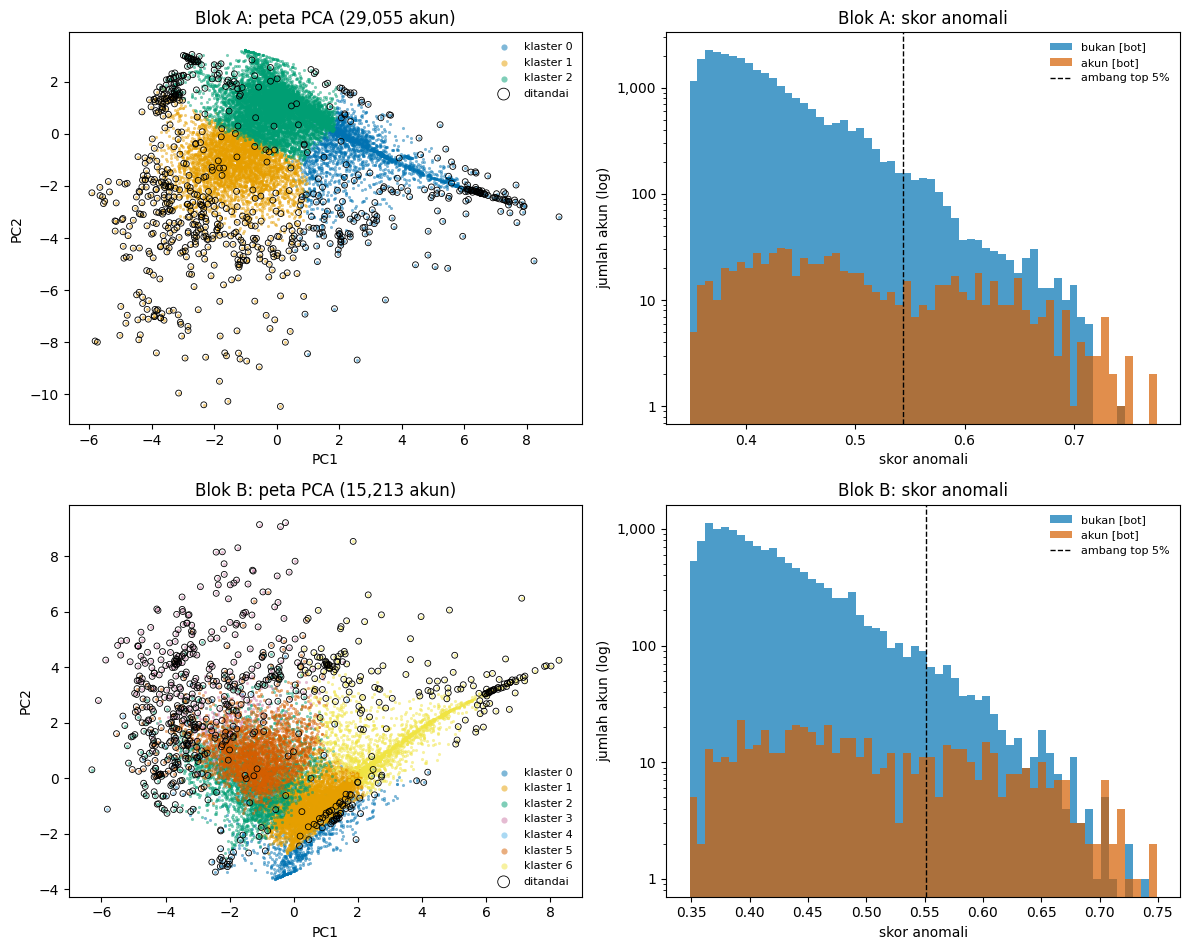

Profil klaster blok A (median per klaster):


,akun,% ditandai,% [bot],n,frac_push,frac_create,frac_pr,frac_issue,frac_social,n_repos,hour_entropy
klaster,,,,,,,,,,,
0,4633,9.4,3.0,131.0,1.00,0.00,0.00,0.0,0.0,1.0,0.93
1,8731,9.7,5.2,31.0,0.61,0.29,0.05,0.0,0.0,3.0,0.76
2,15691,1.1,1.1,30.0,0.98,0.00,0.00,0.0,0.0,1.0,0.70


Profil klaster blok B (median per klaster):


,akun,% ditandai,% [bot],n,frac_push,frac_create,frac_pr,frac_issue,frac_social,n_repos,hour_entropy
klaster,,,,,,,,,,,
0,954,12.7,1.3,47.5,1.00,0.00,0.00,0.00,0.00,1.0,0.29
1,6008,0.0,1.1,29.0,1.00,0.00,0.00,0.00,0.00,1.0,0.76
2,2739,3.5,6.2,31.0,0.75,0.16,0.04,0.00,0.00,8.0,0.75
3,534,42.9,26.6,32.0,0.30,0.10,0.10,0.34,0.00,2.0,0.80
4,58,46.6,0.0,28.0,0.70,0.18,0.02,0.00,0.04,6.0,0.74
5,2984,4.1,4.2,29.0,0.57,0.28,0.10,0.00,0.00,2.0,0.78
6,1936,8.5,3.5,134.0,1.00,0.00,0.00,0.00,0.00,1.0,0.95


In [35]:
OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000"]
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(len(BLOK), 2, figsize=(12, 4.8 * len(BLOK)), squeeze=False)
for i, b in enumerate(BLOK):
    d = HASIL_MODEL[b]
    s = d.iloc[rng.choice(len(d), size=min(15000, len(d)), replace=False)]
    ax = axes[i, 0]
    for k in sorted(d.klaster.unique()):
        t = s[s.klaster == k]
        ax.scatter(t.pc1, t.pc2, s=5, alpha=0.5, color=OKABE[k % len(OKABE)], label=f"klaster {k}", linewidths=0)
    t = s[s.anomali]
    ax.scatter(t.pc1, t.pc2, s=18, facecolors="none", edgecolors="black", linewidths=0.6, label="ditandai")
    ax.set_title(f"Blok {b}: peta PCA ({len(d):,} akun)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(markerscale=2, fontsize=8, frameon=False)
    ax = axes[i, 1]
    bins = np.linspace(d.skor.min(), d.skor.max(), 60)
    ax.hist(d.skor[~d.label_bot], bins=bins, alpha=0.7, color=OKABE[0], label="bukan [bot]")
    ax.hist(d.skor[d.label_bot], bins=bins, alpha=0.7, color=OKABE[5], label="akun [bot]")
    ax.axvline(np.quantile(d.skor, 1 - TOP_PERSEN / 100), color="black", ls="--", lw=1, label=f"ambang top {TOP_PERSEN}%")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
    ax.set_title(f"Blok {b}: skor anomali"); ax.set_xlabel("skor anomali"); ax.set_ylabel("jumlah akun (log)")
    ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(DIR_HASIL / "peta_dan_skor.png", dpi=150)
plt.show()

for b in BLOK:
    d = HASIL_MODEL[b]
    g = d.groupby("klaster")
    prof = g[["n", "frac_push", "frac_create", "frac_pr", "frac_issue", "frac_social", "n_repos", "hour_entropy"]].median().round(2)
    prof.insert(0, "akun", g.size())
    prof.insert(1, "% ditandai", (100 * g.anomali.mean()).round(1))
    prof.insert(2, "% [bot]", (100 * g.label_bot.mean()).round(1))
    print(f"Profil klaster blok {b} (median per klaster):")
    display(prof)

## Kandidat mirip-bot (non-`[bot]`)

Hanya pseudonim yang ditampilkan. Username akun non-bot adalah data pribadi dan tidak boleh muncul di artikel, video, atau repositori. Skor tinggi berarti perilakunya tidak lazim terhadap populasi, bukan bahwa akun itu bot.

In [36]:
for b in BLOK:
    d = HASIL_MODEL[b]
    kand = d[d.anomali & ~d.label_bot].sort_values("skor", ascending=False)
    print(f"Blok {b}: {angka_id(int(d.anomali.sum()))} akun ditandai, {angka_id(len(kand))} di antaranya bukan [bot].")
    t = kand.head(12).copy()
    t.insert(0, "id_anon", [pseudonim(a) for a in t.aid])
    display(t[["id_anon", "n", "n_repos", "frac_push", "frac_create", "hour_entropy", "active_frac", "klaster", "skor"]].round(2))

Blok A: 1.453 akun ditandai, 1.201 di antaranya bukan [bot].


,id_anon,n,n_repos,frac_push,frac_create,hour_entropy,active_frac,klaster,skor
13067,4037fbdfc3d0,3591,2263,0.00,0.00,1.00,1.00,1,0.74
16372,7b646c114d4e,2990,2669,0.01,0.99,0.98,0.88,1,0.72
19402,7b0c7e2155d9,440,90,0.00,1.00,0.20,0.03,1,0.71
9242,e982df367f94,319,1,0.00,1.00,-0.00,0.01,1,0.71
20471,42fe8ecba335,285,1,0.00,1.00,-0.00,0.01,1,0.71
18048,1ff2ec98906f,476,32,0.00,0.99,0.25,0.05,1,0.71
28681,ebfc7c6a75a6,263,1,0.00,1.00,-0.00,0.01,1,0.71
3744,9845e226545f,203,1,0.00,1.00,-0.00,0.01,1,0.71
26710,530364a22c4d,203,1,0.00,1.00,-0.00,0.01,1,0.71
5202,9cbeb7b8ba73,284,10,0.00,1.00,-0.00,0.01,1,0.71


Blok B: 761 akun ditandai, 566 di antaranya bukan [bot].


,id_anon,n,n_repos,frac_push,frac_create,hour_entropy,active_frac,klaster,skor
2271,4037fbdfc3d0,3527,2251,0.00,0.00,1.00,1.00,3,0.74
11178,6aa1f6211075,328,1,0.00,1.00,-0.00,0.01,0,0.72
4370,77cc7edf71f5,353,2,0.00,1.00,-0.00,0.01,0,0.72
5144,24dfc3036ebf,3415,48,0.00,1.00,0.36,0.24,0,0.71
3430,8387f807f549,251,2,0.00,1.00,-0.00,0.03,0,0.71
12971,ef87c2627b10,368,1,0.00,1.00,0.22,0.03,0,0.71
6254,12140c89ef08,190,2,0.00,1.00,0.03,0.03,0,0.70
8956,991d63ba31ce,186,2,0.00,1.00,0.01,0.03,0,0.70
5419,cc7dfe2f2672,132,1,0.00,1.00,-0.00,0.01,0,0.70
13924,142667add021,161,8,0.01,0.99,-0.00,0.01,0,0.70


## 3.4 Ekspor hasil (tanpa username non-bot)

In [37]:
kolom = ["blok", "id_anon", "login_bot", "n", "n_repos", "jam_aktif"] + FITUR + ["skor", "anomali", "klaster", "label_bot"]
for b in BLOK:
    d = HASIL_MODEL[b].copy()
    d["blok"] = b
    d["id_anon"] = [pseudonim(a) for a in d.aid]
    d["login_bot"] = np.where(d.label_bot, d.login, "")           # nama aplikasi [bot] bukan data pribadi
    d[kolom].round(4).to_csv(DIR_HASIL / f"skor_blok_{b}.csv", index=False)
pd.DataFrame(WAKTU).to_csv(DIR_HASIL / "waktu_pipeline.csv", index=False)
VAL.to_csv(DIR_HASIL / "validasi.csv")
SENS.to_csv(DIR_HASIL / "sensitivitas.csv", index=False)
if STAB:
    (DIR_HASIL / "kestabilan.json").write_text(json.dumps(STAB, indent=1))
for p in sorted(DIR_HASIL.iterdir()):
    print(f"{p.name:28s} {p.stat().st_size / 1e6:8.2f} MB")
print("Berkas ini tidak memuat username non-bot. Pseudonim hanya konsisten antar sesi kalau secret HMAC_KEY diisi.")

PRIVAT_kunci_penilaian.csv       0.00 MB
PRIVAT_penilaian_manual.csv      0.00 MB
PRIVAT_penilaian_manual.gsheet     0.00 MB
kestabilan.json                  0.00 MB
kinerja_kueri.csv                0.00 MB
kinerja_kueri.png                0.09 MB
kinerja_ringkasan.csv            0.00 MB
peta_dan_skor.png                0.70 MB
sensitivitas.csv                 0.00 MB
skor_blok_A.csv                  3.20 MB
skor_blok_B.csv                  1.68 MB
validasi.csv                     0.00 MB
waktu_pipeline.csv               0.00 MB
Berkas ini tidak memuat username non-bot. Pseudonim hanya konsisten antar sesi kalau secret HMAC_KEY diisi.


## 3.5 Uji manual, bagian 1: berkas penilaian (PRIVAT)
Membuat sampel akun non-`[bot]` (ditandai vs tidak) untuk dinilai dua penilai. **Berkas memuat username, jangan dibagikan atau dimasukkan ke repo.** Berkas yang sudah ada tidak ditimpa kecuali `TIMPA_SAMPEL_MANUAL = True` (supaya penilaian yang sudah terisi tidak hilang). Matikan dengan `BUAT_SAMPEL_MANUAL = False`.

In [38]:
BERKAS_NILAI = DIR_HASIL / "PRIVAT_penilaian_manual.csv"
if not BUAT_SAMPEL_MANUAL:
    print("BUAT_SAMPEL_MANUAL = False: dilewati.")
elif BERKAS_NILAI.exists() and not TIMPA_SAMPEL_MANUAL:
    print(f"{BERKAS_NILAI.name} sudah ada: tidak ditimpa (set TIMPA_SAMPEL_MANUAL = True untuk membuat ulang).")
else:
    rng = np.random.default_rng(SEED)
    baris = []
    for b in BLOK:
        d = HASIL_MODEL[b]
        d = d[~d.label_bot]                                  # hanya akun non-[bot]
        for nama, g in (("ditandai", d[d.anomali]), ("tidak ditandai", d[~d.anomali])):
            s = g.iloc[rng.choice(len(g), size=min(N_PER_KELOMPOK, len(g)), replace=False)]
            for _, r in s.iterrows():
                baris.append({"blok": b, "aid": int(r.aid), "login": r.login, "kelompok": nama, "n": int(r.n),
                              "n_repos": int(r.n_repos), "jam_aktif": int(r.jam_aktif),
                              "frac_push": round(r.frac_push, 2), "frac_create": round(r.frac_create, 2),
                              "frac_pr": round(r.frac_pr, 2), "frac_issue": round(r.frac_issue, 2),
                              "frac_social": round(r.frac_social, 2)})
    sampel = pd.DataFrame(baris).sample(frac=1, random_state=SEED).reset_index(drop=True)   # diacak: penilai buta
    sampel.insert(0, "no", range(1, len(sampel) + 1))
    sampel["profil_github"] = "https://github.com/" + sampel.login

    nilai = sampel[["no", "login", "profil_github", "n", "n_repos", "jam_aktif",
                    "frac_push", "frac_create", "frac_pr", "frac_issue", "frac_social"]].copy()
    nilai["penilai1"] = ""
    nilai["penilai2"] = ""
    nilai.to_csv(DIR_HASIL / "PRIVAT_penilaian_manual.csv", index=False)
    sampel[["no", "blok", "aid", "kelompok"]].to_csv(DIR_HASIL / "PRIVAT_kunci_penilaian.csv", index=False)

    print(f"{len(sampel)} akun dalam sampel ({sampel.kelompok.value_counts().to_dict()}).")
    print("PRIVAT_penilaian_manual.csv  -> berikan ke DUA penilai (jangan ke orang lain, jangan ke repo).")
    print("  Tiap penilai membuka profil GitHub tiap akun, lalu mengisi kolomnya sendiri tanpa berdiskusi:")
    print("    bot   = pola jelas otomatis (profil menyebut otomasi/bot, atau aktivitas masif tanpa pola manusia)")
    print("    bukan = jelas manusia (profil dan aktivitas wajar)")
    print("    ragu  = tidak bisa ditentukan dari data publik")
    print("PRIVAT_kunci_penilaian.csv   -> simpan sendiri. Berisi kelompok ditandai/tidak. JANGAN diberikan ke penilai.")
    print("Kedua berkas memuat username akun non-bot. Hapus setelah selesai dan jangan masukkan ke dataset yang dikumpulkan.")

PRIVAT_penilaian_manual.csv sudah ada: tidak ditimpa (set TIMPA_SAMPEL_MANUAL = True untuk membuat ulang).


## 3.6 Sinkronisasi hasil model ke Atlas (untuk Atlas Charts)

Hasil model per akun ditulis ke koleksi `ghbots.user_scores` supaya bisa dipakai di Atlas Charts. Satu dokumen per akun per blok, kuncinya `(blok, id_anon)`.

- `id_anon` adalah pseudonim HMAC yang sama dengan berkas CSV. **Username akun non-bot tidak ditulis.** Nama login hanya disimpan untuk akun `[bot]` (nama aplikasi, bukan data pribadi).
- Penulisan memakai upsert per batch, jadi sel ini aman dijalankan ulang (idempotent) dan tidak menggandakan dokumen.
- Jalankan setelah sel model (`HASIL_MODEL`) dan sel pseudonim (3.1) selesai.

In [39]:
KOLOM_RINGKAS = ["n_repos", "jam_aktif", "frac_push", "frac_create", "frac_pr", "frac_issue", "frac_social",
                 "max_repo_share", "hour_entropy", "active_frac"]
skor_col.create_index([("blok", ASCENDING), ("id_anon", ASCENDING)], unique=True, name="blok_id_anon_unik")
skor_col.create_index([("blok", ASCENDING), ("ditandai", ASCENDING), ("skor_anomali", -1)], name="blok_ditandai_skor")

waktu_sync = datetime.now(timezone.utc)
for b in BLOK:
    d = HASIL_MODEL[b]
    ops = []
    for r in d.itertuples(index=False):
        doc = {
            "blok": b,
            "id_anon": pseudonim(r.aid),
            "skor_anomali": round(float(r.skor), 5),
            "ditandai": bool(r.anomali),
            "klaster": int(r.klaster),
            "pc1": round(float(r.pc1), 5),
            "pc2": round(float(r.pc2), 5),
            "is_bot_label": bool(r.label_bot),
            "n_events": int(r.n),
            "login_bot": r.login if r.label_bot else None,      # hanya nama aplikasi [bot]
            "diperbarui": waktu_sync,
        }
        for k in KOLOM_RINGKAS:
            v = getattr(r, k)
            doc[k] = int(v) if k in ("n_repos", "jam_aktif") else round(float(v), 4)
        ops.append(UpdateOne({"blok": b, "id_anon": doc["id_anon"]}, {"$set": doc}, upsert=True))
    for i in tqdm(range(0, len(ops), BATCH_SINKRON), desc=f"Sinkron blok {b}"):
        skor_col.bulk_write(ops[i:i + BATCH_SINKRON], ordered=False)
    print(f"Blok {b}: {angka_id(len(ops))} akun ditulis ke ghbots.user_scores.")

Sinkron blok A:   0%|          | 0/15 [00:00<?, ?it/s]

Blok A: 29.055 akun ditulis ke ghbots.user_scores.


Sinkron blok B:   0%|          | 0/8 [00:00<?, ?it/s]

Blok B: 15.213 akun ditulis ke ghbots.user_scores.


### Verifikasi sinkronisasi

Jumlah dokumen per blok di Atlas harus sama dengan jumlah akun yang masuk model.

In [40]:
semua_cocok = True
for b in BLOK:
    di_atlas = skor_col.count_documents({"blok": b})
    di_model = len(HASIL_MODEL[b])
    ditandai = skor_col.count_documents({"blok": b, "ditandai": True})
    cocok = di_atlas == di_model
    semua_cocok &= cocok
    print(f"Blok {b}: Atlas {angka_id(di_atlas)} | model {angka_id(di_model)} | ditandai {angka_id(ditandai)} | {'SESUAI' if cocok else 'TIDAK SESUAI'}")
if not semua_cocok:
    print("Ada selisih. Kemungkinan dokumen lama dari run dengan MIN_MODEL atau HMAC_KEY berbeda. Hapus koleksi user_scores lalu jalankan ulang sel sinkronisasi.")
# Pastikan tidak ada username non-bot yang bocor ke koleksi
bocor = skor_col.count_documents({"is_bot_label": False, "login_bot": {"$ne": None}})
print(f"Dokumen non-bot yang memuat login: {bocor} (harus 0)")

Blok A: Atlas 58.110 | model 29.055 | ditandai 2.906 | TIDAK SESUAI
Blok B: Atlas 30.426 | model 15.213 | ditandai 1.522 | TIDAK SESUAI
Ada selisih. Kemungkinan dokumen lama dari run dengan MIN_MODEL atau HMAC_KEY berbeda. Hapus koleksi user_scores lalu jalankan ulang sel sinkronisasi.
Dokumen non-bot yang memuat login: 0 (harus 0)


### 3.7 Panduan dashboard Atlas Charts

1. Di Atlas buka **Charts**, buat dashboard baru, lalu **Add Data Source** dan pilih cluster, database `ghbots`, koleksi `user_scores`.
2. **Scatter**: X = `pc1`, Y = `pc2`. Warnai dengan `klaster`. Buat satu grafik lagi dengan warna `ditandai` untuk melihat letak kandidat. Pada data besar, atur batas titik atau pakai sampel.
3. **Bar**: kategori = `klaster`, nilai = hitungan dokumen (`COUNT`). Opsional pecah (series) dengan `ditandai` atau `is_bot_label`.
4. **Tabel top kandidat**: filter `ditandai = true` dan `is_bot_label = false`, urutkan `skor_anomali` menurun, batas 20 baris. Kolom: `id_anon`, `skor_anomali`, `klaster`, `n_events`, `n_repos`, `hour_entropy`.
5. **Filter blok**: tambahkan *dashboard filter* pada field `blok` agar semua grafik bisa dipindah antara A dan B.

> **Pengingat:** jangan membagikan connection string Atlas (di dashboard, tangkapan layar, atau repositori). Gunakan tautan *embed* atau berbagi publik hanya untuk dashboard yang datanya sudah dipseudonimkan. Jangan menambahkan login akun non-bot ke koleksi ini. Akun ditandai tinggi adalah **kandidat mirip-bot**, bukan bot yang terbukti.

### 3.8 (Opsional) Uji manual, bagian 2: kesepakatan dan presisi
Jalankan **setelah kedua penilai selesai** mengisi `PRIVAT_penilaian_manual.csv`: set `JALANKAN_OPSIONAL = True` dan `HITUNG_UJI_MANUAL = True`, lalu jalankan sel ini saja (atau ulang dari Pengaturan). Ringkasan yang disimpan tidak memuat username.

In [ ]:
if JALANKAN_OPSIONAL and HITUNG_UJI_MANUAL:
    nil = pd.read_csv(DIR_HASIL / "PRIVAT_penilaian_manual.csv")
    kunci_nilai = pd.read_csv(DIR_HASIL / "PRIVAT_kunci_penilaian.csv")
    d = nil.merge(kunci_nilai, on="no")
    pemetaan = {"1": "bot", "1.0": "bot", "0": "bukan", "0.0": "bukan", "bot": "bot", "bukan": "bukan", "ragu": "ragu"}
    for k in ("penilai1", "penilai2"):
        d[k] = d[k].astype(str).str.strip().str.lower().map(pemetaan).fillna("ragu")
    sah = {"bot", "bukan", "ragu"}
    L = d[d.penilai1.isin(sah) & d.penilai2.isin(sah)].copy()
    print(f"Baris terisi lengkap oleh kedua penilai: {len(L)} dari {len(d)}")
    if len(L) < 10:
        raise RuntimeError("Belum cukup baris yang diisi kedua penilai (nilai sah: bot / bukan / ragu). Isi dulu, simpan CSV, lalu jalankan ulang sel ini.")

    kappa = cohen_kappa_score(L.penilai1, L.penilai2)
    print(f"Kesepakatan mentah: {(L.penilai1 == L.penilai2).mean():.1%} | Cohen's kappa: {kappa:.3f}")

    L["konsensus"] = np.where(L.penilai1 == L.penilai2, L.penilai1, "tidak sepakat")
    tab = pd.crosstab(L.kelompok, L.konsensus)
    display(tab)

    def wilson(k, n, z=1.96):
        if n == 0:
            return (np.nan, np.nan)
        p = k / n
        pen = 1 + z * z / n
        pusat = (p + z * z / (2 * n)) / pen
        lebar = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / pen
        return (pusat - lebar, pusat + lebar)

    rows_manual = []
    for kel, g in L.groupby("kelompok"):
        pasti = g[g.konsensus.isin(["bot", "bukan"])]           # 'ragu' dan 'tidak sepakat' dikeluarkan
        k, n = int((pasti.konsensus == "bot").sum()), len(pasti)
        lo, hi = wilson(k, n)
        rows_manual.append({"kelompok": kel, "dinilai_pasti": n, "dinilai_bot": k,
                      "persen_bot": round(100 * k / n, 1) if n else np.nan,
                      "CI95_bawah": round(100 * max(lo, 0), 1), "CI95_atas": round(100 * min(hi, 1), 1)})
    HASIL_MANUAL = pd.DataFrame(rows_manual)
    display(HASIL_MANUAL)
    HASIL_MANUAL.assign(kappa=round(kappa, 3), n_sampel=len(L)).to_csv(DIR_HASIL / "uji_manual_ringkasan.csv", index=False)
    print("Ringkasan tanpa username tersimpan di uji_manual_ringkasan.csv (aman dilaporkan).")
else:
    print('Dilewati (butuh JALANKAN_OPSIONAL = True dan HITUNG_UJI_MANUAL = True).')

Baris terisi lengkap oleh kedua penilai: 0 dari 60


RuntimeError: Belum cukup baris yang diisi kedua penilai (nilai sah: bot / bukan / ragu). Isi dulu, simpan CSV, lalu jalankan ulang sel ini.

### Selesai Bagian 3
- Profil di `ghbots.user_profiles`, skor di `ghbots.user_scores`; CSV, grafik, waktu pipeline, validasi di folder hasil.
- `waktu_pipeline.csv`, `validasi.csv`, `sensitivitas.csv`, `kestabilan.json` adalah bahan langsung untuk bagian hasil artikel.
- Model machine learning (`.joblib`), metadata anomali, dan karakteristik klaster (`.json`) tersimpan di `DIR_HASIL / "models"` untuk web dashboard.

# Bagian 4: Benchmark kinerja kueri NoSQL

Pertanyaan: seberapa besar indeks mempercepat kueri di MongoDB Atlas, dan bagaimana waktu kueri bertambah ketika data yang dibaca membesar?

**Rancangan**
- Ukuran data: jendela waktu yang makin lebar dari `MULAI_UJI` (default awal blok A), lebar `UKURAN_JAM`. Jumlah dokumen sebenarnya dihitung dan dipakai sebagai sumbu x.
- Kueri agregasi pada rentang waktu: event per tipe (Q1), event per jam (Q2), 10 akun teraktif (Q3); pencarian semua event satu akun (Q4, 3 akun: median, p90, terbanyak); event per akun dalam satu blok (Q5, deteksi bot).
- Dua kondisi, kueri persis sama: **tanpa indeks** (`hint {$natural: 1}`, memindai seluruh koleksi) dan **dengan indeks** (penyusun rencana bebas memilih `ts_1` atau `blok_aid_ts`).
- Tiap titik dengan indeks diukur `ULANGI` kali setelah satu pemanasan; tanpa indeks `ULANGI_TANPA_INDEKS` kali tanpa pemanasan. Yang dilaporkan median dan rentang min-maks.
- Rencana eksekusi (`explain`) direkam sebagai bukti kondisi benar-benar memakai indeks atau memindai koleksi.

Hasil bergantung pada tier cluster (M10), cache, dan beban Atlas. Laporkan sebagai "pada M10, satu kali sesi pengukuran".

## 4.1 Indeks yang tersedia
Indeks `blok_aid_ts` dibuat di Bagian 2. Kueri rentang waktu tidak bisa memakai awalan `blok, aid`, jadi dibuat indeks tambahan `ts_1` (sekali, sekitar satu sampai dua menit).

In [ ]:
ada = {i["name"] for i in raw.list_indexes()}
if "ts_1" not in ada:
    t0 = time.time()
    raw.create_index([("ts", 1)], name="ts_1")
    print(f"Indeks ts_1 dibuat ({time.time() - t0:.0f} dtk).")
try:
    st = db.command("collStats", "raw_events", scale=1024 * 1024)
    print("Indeks:", {k: f"{v:,.0f} MB" for k, v in st["indexSizes"].items()})
    print(f"Data {st['size']:,.0f} MB | di disk {st['storageSize']:,.0f} MB | dokumen {angka_id(st['count'])}")
except OperationFailure:
    print("Perintah collStats tidak tersedia di cluster ini; ukuran indeks bisa dilihat di Atlas -> Collections.")

Indeks ts_1 dibuat (31 dtk).
Indeks: {'_id_': '286 MB', 'ts_1': '100 MB'}
Data 975 MB | di disk 438 MB | dokumen 9.884.213


## 4.2 Susunan kueri

In [ ]:
HINT_NATURAL = {"$natural": 1}

def filter_waktu(jam):
    return {"ts": {"$gte": T0_UJI, "$lt": T0_UJI + timedelta(hours=jam)}}

def kueri_agregasi(jam):
    f = [{"$match": filter_waktu(jam)}]
    return {
        "Q1 event per tipe": f + [{"$group": {"_id": "$t", "n": {"$sum": 1}}}],
        "Q2 event per jam": f + [{"$group": {"_id": {"$dateToString": {"format": "%Y-%m-%dT%H", "date": "$ts"}},
                                              "n": {"$sum": 1}}}],
        "Q3 10 akun teraktif": f + [{"$group": {"_id": "$aid", "n": {"$sum": 1}}},
                                    {"$sort": {"n": -1}}, {"$limit": 10}],
    }

def tebar(node, hasil):
    """Kumpulkan nama tahap dan indeks dari keluaran explain (struktur bersarang)."""
    if isinstance(node, dict):
        for k, v in node.items():
            if k == "stage" and isinstance(v, str):
                hasil["tahap"].add(v)
            elif k == "indexName" and isinstance(v, str):
                hasil["indeks"].add(v)
            else:
                tebar(v, hasil)
    elif isinstance(node, list):
        for x in node:
            tebar(x, hasil)

def rencana(perintah):
    hasil = {"tahap": set(), "indeks": set()}
    tebar(db.command({"explain": perintah, "verbosity": "queryPlanner"}), hasil)
    pakai = ",".join(sorted(hasil["indeks"])) or "-"
    return ("COLLSCAN" if "COLLSCAN" in hasil["tahap"] else "IXSCAN" if "IXSCAN" in hasil["tahap"] else "?"), pakai

def ukur(fn, ulangi, pemanasan=True):
    """Pemanasan opsional, lalu `ulangi` pengukuran. Mengembalikan (daftar detik, status).
    Kueri yang melewati BATAS_DETIK dicatat sebagai nilai batas (status "timeout"), bukan error."""
    waktu = []
    try:
        if pemanasan:
            fn()
        for _ in range(ulangi):
            t0 = time.time(); fn(); waktu.append(time.time() - t0)
        return waktu, "ok"
    except ExecutionTimeout:
        return waktu + [float(BATAS_DETIK)], "timeout"
    except OperationFailure as e:
        if e.code == 50:          # MaxTimeMSExpired
            return waktu + [float(BATAS_DETIK)], "timeout"
        raise

## 4.3 Jalankan eksperimen

Tanpa indeks memindai seluruh koleksi untuk **tiap** kueri, berapa pun lebar jendelanya, jadi bagian ini yang paling lama. Untuk membatasi waktu:
- tanpa indeks hanya diukur pada `UKURAN_TANPA_INDEKS` dengan `ULANGI_TANPA_INDEKS` ulangan dan tanpa pemanasan; dengan indeks diukur penuh;
- tiap eksekusi dibatasi `BATAS_DETIK` (`maxTimeMS`). Yang melewati batas dicatat `status = timeout` dengan nilai sama dengan batas (percepatan menjadi **batas bawah**). Bila satu kueri sudah timeout tanpa indeks, ukuran berikutnya dicatat `timeout_dilewati`;
- tiap titik langsung disimpan ke `kinerja_kueri.csv` (checkpoint). Kalau sel terhenti atau diulang, titik yang selesai dibaca kembali dan dilewati. **Hapus file itu untuk mengukur dari awal** (wajib kalau pengaturan Bagian 4 diubah).

In [ ]:
KONDISI = {"tanpa indeks": HINT_NATURAL, "dengan indeks": None}
BERKAS = DIR_HASIL / "kinerja_kueri.csv"
KOLOM = ["kueri", "jam", "dokumen", "kondisi", "ulangan", "status", "median_dtk", "min_dtk", "maks_dtk", "rencana", "indeks_dipakai"]

def kunci_titik(kueri, jam, kond):
    return (kueri, -1 if jam is None or pd.isna(jam) else int(jam), kond)

# resume: baca titik yang sudah selesai
baris, selesai = [], set()
if BERKAS.exists():
    lama = pd.read_csv(BERKAS)
    if "status" in lama.columns:
        baris = lama.to_dict("records")
        selesai = {kunci_titik(r["kueri"], r["jam"], r["kondisi"]) for r in baris}
        print(f"Resume: {len(selesai)} titik sudah ada di {BERKAS.name}, dilewati.")
    else:
        print("Berkas lama tanpa kolom status diabaikan (akan ditimpa).")

def simpan(r):
    baris.append(r); selesai.add(kunci_titik(r["kueri"], r["jam"], r["kondisi"]))
    pd.DataFrame(baris, columns=KOLOM).to_csv(BERKAS, index=False)      # checkpoint tiap titik

# ---- daftar tugas ----
tugas = []     # (kueri, jam, dokumen, kondisi, jenis, objek)
for jam in UKURAN_UJI:
    n_dok = raw.count_documents(filter_waktu(jam), maxTimeMS=BATAS_DETIK * 1000)
    if n_dok == 0:
        print(f"Jendela {jam} jam kosong, dilewati."); continue
    for nama, pipe in kueri_agregasi(jam).items():
        for kond in KONDISI:
            if kond == "tanpa indeks" and jam not in UKURAN_UJI_TANPA:
                continue
            tugas.append((nama, jam, n_dok, kond, "agg", pipe))

# pemilihan akun untuk Q4 dan blok untuk Q5 (deteksi bot)
blok_uji = sorted(d["_id"] for d in db["windows"].find({}))[0]
prof = pd.DataFrame(list(profil.find({"blok": blok_uji}, {"aid": 1, "n": 1}))).sort_values("n").reset_index(drop=True)
if len(prof) >= 3:
    pilih = {"akun median": prof.iloc[len(prof) // 2], "akun p90": prof.iloc[int(len(prof) * 0.9)], "akun terbanyak": prof.iloc[-1]}
    for nama, r in pilih.items():
        for kond in KONDISI:
            tugas.append((f"Q4 semua event satu akun ({nama}, {int(r.n)} event)", None, int(r.n), kond, "find", {"blok": blok_uji, "aid": int(r.aid)}))
n_blok = raw.count_documents({"blok": blok_uji}, maxTimeMS=BATAS_DETIK * 1000)
pipe_bot = [{"$match": {"blok": blok_uji}}, {"$group": {"_id": "$aid", "n": {"$sum": 1}}}, {"$sort": {"n": -1}}, {"$limit": 10}]
for kond in KONDISI:
    tugas.append(("Q5 bot: event per akun dalam satu blok (10 teratas)", None, n_blok, kond, "agg_blok", pipe_bot))

# ---- eksekusi ----
sisa = [t for t in tugas if kunci_titik(t[0], t[1], t[3]) not in selesai]
print(f"{len(tugas)} titik total, {len(sisa)} perlu diukur. Batas {BATAS_DETIK} dtk per eksekusi.")
durasi = {"tanpa indeks": [], "dengan indeks": []}
t_mulai_uji = time.time()
timeout_scan = {r["kueri"] for r in baris if r["kondisi"] == "tanpa indeks" and r["status"] in ("timeout", "timeout_dilewati")}

def perkiraan_sisa(i):
    sisa_k = {k: sum(1 for t in sisa[i + 1:] if t[3] == k) for k in durasi}
    est = 0
    for k, n in sisa_k.items():
        rata = statistics.mean(durasi[k]) if durasi[k] else (BATAS_DETIK / 2 if k == "tanpa indeks" else 20)
        est += n * rata
    return est

def fmt(d):
    d = int(d); return f"{d // 60}m{d % 60:02d}s"

try:
    for i, (nama, jam, n_dok, kond, jenis, obj) in enumerate(sisa):
        hint = KONDISI[kond]
        t_titik = time.time()
        if kond == "tanpa indeks" and nama in timeout_scan:
            r = dict(kueri=nama, jam=jam, dokumen=n_dok, kondisi=kond, ulangan=0, status="timeout_dilewati",
                     median_dtk=float(BATAS_DETIK), min_dtk=float(BATAS_DETIK), maks_dtk=float(BATAS_DETIK), rencana="COLLSCAN", indeks_dipakai="-")
            simpan(r); print(f"[{i+1}/{len(sisa)}] {nama} {jam or ''} {kond}: dilewati (timeout sebelumnya)"); continue
        ulangi = ULANGI_TANPA_INDEKS if kond == "tanpa indeks" else ULANGI
        pemanasan = kond != "tanpa indeks"
        if jenis in ("agg", "agg_blok"):
            kw = {"allowDiskUse": True, "maxTimeMS": BATAS_DETIK * 1000}
            if hint: kw["hint"] = hint
            fn = lambda: list(raw.aggregate(obj, **kw))
            cmd = {"aggregate": "raw_events", "pipeline": obj, "cursor": {}}
        else:
            def fn():
                c = raw.find(obj, max_time_ms=BATAS_DETIK * 1000)
                if hint: c = c.hint(hint)
                return list(c)
            cmd = {"find": "raw_events", "filter": obj}
        if hint: cmd["hint"] = HINT_NATURAL
        w, status = ukur(fn, ulangi, pemanasan)
        try:
            plan, idx = rencana(cmd)
        except OperationFailure:
            plan, idx = "?", "-"
        if status == "timeout" and kond == "tanpa indeks":
            timeout_scan.add(nama)
        d = 4 if jenis == "find" else 3
        simpan(dict(kueri=nama, jam=jam, dokumen=n_dok, kondisi=kond, ulangan=len(w), status=status,
                    median_dtk=round(statistics.median(w), d), min_dtk=round(min(w), d), maks_dtk=round(max(w), d),
                    rencana=plan, indeks_dipakai=idx))
        durasi[kond].append(time.time() - t_titik)
        print(f"[{i+1}/{len(sisa)}] {nama} {jam or ''} {kond}: {w and round(statistics.median(w), 2)} dtk ({status}, {plan}) | "
              f"lewat {fmt(time.time() - t_mulai_uji)}, sisa ~{fmt(perkiraan_sisa(i))}")
except KeyboardInterrupt:
    print("Dihentikan. Hasil sampai titik terakhir sudah tersimpan; jalankan sel ini lagi untuk melanjutkan.")

KINERJA = pd.DataFrame(baris, columns=KOLOM)
print(f"Selesai {len(selesai)}/{len(tugas)} titik. Total sesi ini {fmt(time.time() - t_mulai_uji)}.")
display(KINERJA)

32 titik total, 32 perlu diukur. Batas 150 dtk per eksekusi.
[1/32] Q1 event per tipe 6 tanpa indeks: 6.15 dtk (ok, COLLSCAN) | lewat 0m06s, sisa ~7m36s
[2/32] Q1 event per tipe 6 dengan indeks: 0.78 dtk (ok, IXSCAN) | lewat 0m10s, sisa ~2m22s
[3/32] Q2 event per jam 6 tanpa indeks: 6.21 dtk (ok, COLLSCAN) | lewat 0m16s, sisa ~2m16s
[4/32] Q2 event per jam 6 dengan indeks: 0.69 dtk (ok, IXSCAN) | lewat 0m19s, sisa ~2m06s
[5/32] Q3 10 akun teraktif 6 tanpa indeks: 5.95 dtk (ok, COLLSCAN) | lewat 0m25s, sisa ~1m59s
[6/32] Q3 10 akun teraktif 6 dengan indeks: 1.15 dtk (ok, IXSCAN) | lewat 0m30s, sisa ~2m04s
[7/32] Q1 event per tipe 12 dengan indeks: 1.35 dtk (ok, IXSCAN) | lewat 0m35s, sisa ~2m07s
[8/32] Q2 event per jam 12 dengan indeks: 1.17 dtk (ok, IXSCAN) | lewat 0m40s, sisa ~2m04s
[9/32] Q3 10 akun teraktif 12 dengan indeks: 2.09 dtk (ok, IXSCAN) | lewat 0m49s, sisa ~2m09s
[10/32] Q1 event per tipe 24 tanpa indeks: 5.9 dtk (ok, COLLSCAN) | lewat 0m55s, sisa ~2m02s
[11/32] Q1 event p

,kueri,jam,dokumen,kondisi,ulangan,status,median_dtk,min_dtk,maks_dtk,rencana,indeks_dipakai
0,Q1 event per tipe,6.0,490725,tanpa indeks,1,ok,6.1520,6.1520,6.1520,COLLSCAN,-
1,Q1 event per tipe,6.0,490725,dengan indeks,3,ok,0.7780,0.7620,0.8170,IXSCAN,ts_1
2,Q2 event per jam,6.0,490725,tanpa indeks,1,ok,6.2130,6.2130,6.2130,COLLSCAN,-
3,Q2 event per jam,6.0,490725,dengan indeks,3,ok,0.6920,0.6790,0.6960,IXSCAN,ts_1
4,Q3 10 akun teraktif,6.0,490725,tanpa indeks,1,ok,5.9510,5.9510,5.9510,COLLSCAN,-
5,Q3 10 akun teraktif,6.0,490725,dengan indeks,3,ok,1.1460,1.1360,1.1520,IXSCAN,ts_1
6,Q1 event per tipe,12.0,981326,dengan indeks,3,ok,1.3520,1.3480,1.3610,IXSCAN,ts_1
7,Q2 event per jam,12.0,981326,dengan indeks,3,ok,1.1710,1.1660,1.1780,IXSCAN,ts_1
8,Q3 10 akun teraktif,12.0,981326,dengan indeks,3,ok,2.0860,2.0670,2.1250,IXSCAN,ts_1
9,Q1 event per tipe,24.0,1864673,tanpa indeks,1,ok,5.8990,5.8990,5.8990,COLLSCAN,-


## 4.4 Ringkasan: percepatan oleh indeks

Percepatan = waktu tanpa indeks dibagi waktu dengan indeks, untuk kueri dan ukuran yang sama. Baris dengan `rencana` yang tidak sesuai kondisi (misalnya "dengan indeks" tetapi tetap `COLLSCAN`) berarti penyusun rencana memilih tidak memakai indeks. Itu hasil sah dan harus ditulis apa adanya. Kalau tanpa indeks `timeout`, nilainya adalah batas waktu sehingga percepatan adalah batas bawah (kolom `batas_bawah`). Titik yang belum diukur (hasil parsial) tampil kosong.

In [ ]:
K = KINERJA.assign(jam=KINERJA.jam.fillna(0).astype(int))      # Q4 dan Q5 tidak punya jendela jam
kunci_gabung = ["kueri", "jam", "dokumen"]
kol_a = ["median_dtk", "rencana", "status"]
a = K[K.kondisi == "tanpa indeks"].set_index(kunci_gabung)[kol_a].add_suffix("_a")
b = K[K.kondisi == "dengan indeks"].set_index(kunci_gabung)[kol_a + ["indeks_dipakai"]].add_suffix("_b")
pv = a.join(b, how="outer").reset_index()
pv = pv.rename(columns={"median_dtk_a": "tanpa_indeks_dtk", "median_dtk_b": "dengan_indeks_dtk", "rencana_a": "rencana_tanpa_indeks",
                        "rencana_b": "rencana_dengan_indeks", "indeks_dipakai_b": "indeks_dipakai",
                        "status_a": "status_tanpa_indeks", "status_b": "status_dengan_indeks"})
pv["percepatan_x"] = (pv.tanpa_indeks_dtk / pv.dengan_indeks_dtk).round(1)
pv["batas_bawah"] = pv.status_tanpa_indeks.isin(["timeout", "timeout_dilewati"])
display(pv)
pv.to_csv(DIR_HASIL / "kinerja_ringkasan.csv", index=False)

,kueri,jam,dokumen,tanpa_indeks_dtk,rencana_tanpa_indeks,status_tanpa_indeks,dengan_indeks_dtk,rencana_dengan_indeks,status_dengan_indeks,indeks_dipakai,percepatan_x,batas_bawah
0,Q1 event per tipe,6,490725,6.1520,COLLSCAN,ok,0.7780,IXSCAN,ok,ts_1,7.9,False
1,Q1 event per tipe,12,981326,NaN,NaN,NaN,1.3520,IXSCAN,ok,ts_1,NaN,False
2,Q1 event per tipe,24,1864673,5.8990,COLLSCAN,ok,2.4330,IXSCAN,ok,ts_1,2.4,False
3,Q1 event per tipe,48,3775448,NaN,NaN,NaN,4.7700,IXSCAN,ok,ts_1,NaN,False
4,Q1 event per tipe,78,6244807,7.2320,COLLSCAN,ok,8.5720,IXSCAN,ok,ts_1,0.8,False
5,Q2 event per jam,6,490725,6.2130,COLLSCAN,ok,0.6920,IXSCAN,ok,ts_1,9.0,False
6,Q2 event per jam,12,981326,NaN,NaN,NaN,1.1710,IXSCAN,ok,ts_1,NaN,False
7,Q2 event per jam,24,1864673,6.6390,COLLSCAN,ok,2.0670,IXSCAN,ok,ts_1,3.2,False
8,Q2 event per jam,48,3775448,NaN,NaN,NaN,4.0110,IXSCAN,ok,ts_1,NaN,False
9,Q2 event per jam,78,6244807,10.7280,COLLSCAN,ok,6.5100,IXSCAN,ok,ts_1,1.6,False


## 4.5 Grafik

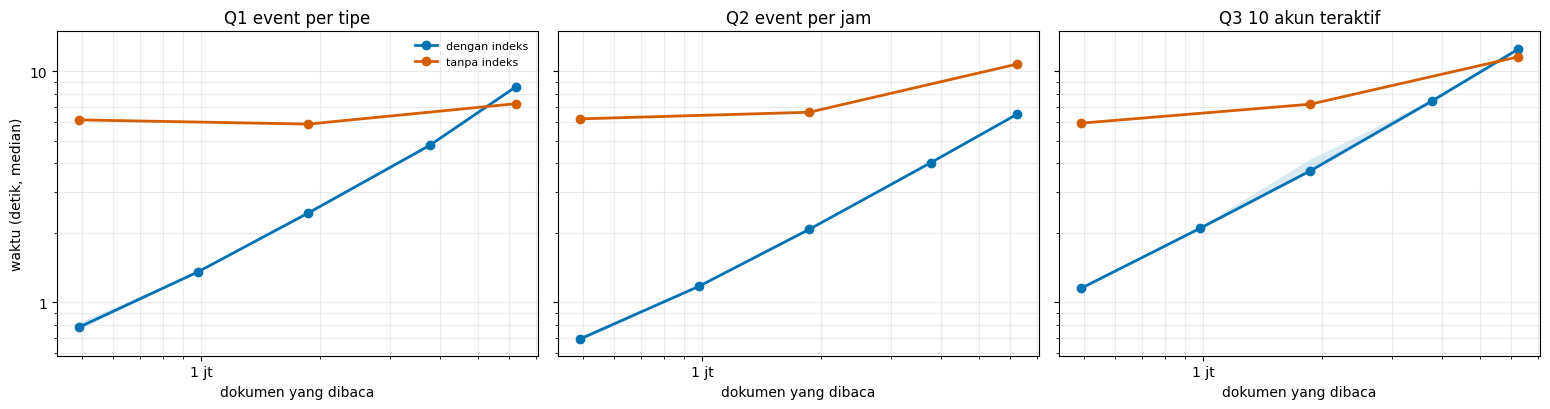

In [ ]:
WARNA_KONDISI = {"tanpa indeks": "#D55E00", "dengan indeks": "#0072B2"}
agr = KINERJA[KINERJA.kueri.str.startswith(("Q1", "Q2", "Q3"))].dropna(subset=["median_dtk"])
nama_q = sorted(agr.kueri.unique())
if not nama_q:
    raise SystemExit("Belum ada hasil Q1-Q3 untuk digambar; jalankan sel eksperimen dulu.")
fig, axes = plt.subplots(1, len(nama_q), figsize=(5.2 * len(nama_q), 4.2), sharey=True, squeeze=False)
for ax, q in zip(axes[0], nama_q):
    for kond, g in agr[agr.kueri == q].groupby("kondisi"):
        g = g.sort_values("dokumen")
        ax.plot(g.dokumen, g.median_dtk, marker="o", color=WARNA_KONDISI[kond], label=kond, lw=2)
        to = g[g.status.isin(["timeout", "timeout_dilewati"])]
        if len(to):
            ax.scatter(to.dokumen, to.median_dtk, marker="X", s=90, color=WARNA_KONDISI[kond], edgecolor="k", zorder=5,
                       label=f"{kond} (timeout, batas)")
        ax.fill_between(g.dokumen, g.min_dtk, g.maks_dtk, color=WARNA_KONDISI[kond], alpha=0.15, linewidth=0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1e6:g} jt" if v >= 1e6 else f"{v/1e3:g} rb"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_title(q); ax.set_xlabel("dokumen yang dibaca"); ax.grid(alpha=0.25, which="both")
axes[0][0].set_ylabel("waktu (detik, median)")
axes[0][0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(DIR_HASIL / "kinerja_kueri.png", dpi=150)
plt.show()

### Selesai Bagian 4 (dan seluruh pipeline)
- `kinerja_kueri.csv` (semua pengukuran + status), `kinerja_ringkasan.csv` (percepatan), `kinerja_kueri.png` ada di folder hasil.
- Untuk artikel, laporkan: tier cluster (M10), jumlah ulangan (dengan indeks `ULANGI`, tanpa indeks `ULANGI_TANPA_INDEKS`, tanpa pemanasan), median (rentang min-maks), `BATAS_DETIK` dan titik yang timeout (percepatan batas bawah), serta rencana eksekusi tiap kondisi.
- Kalau data diperluas, ubah `UKURAN_JAM`/`UKURAN_TANPA_INDEKS`, hapus `kinerja_kueri.csv`, lalu jalankan ulang.